# 06 - RQ3 — Diagnostic Analysis of Geographic Denial Gaps

**Project:** Group 7 — HMDA Mortgage Lending Analysis  
**Dataset:** 2024 HMDA cleaned in-scope applications  
**Input file:** `hmda_clean_v1.parquet`

## Research question

How do state-to-national mortgage-denial gaps change after adjustment for observable financial and loan characteristics, and does lender mix matter?

## Analysis design

1. Use **50 U.S. states plus the District of Columbia (DC)** for the national raw geographic reference rate, matching the Group 7 RQ1 convention. Exclude U.S. territories and unrecognized geographic codes from geographic comparisons. Select focus states using a minimum of 10,000 decisions per jurisdiction.
2. Identify the five highest and five lowest raw denial rates among eligible states, with Wilson 95% intervals.
3. Perform direct standardization using nationally weighted `income_band`, `dti_band`, `loan_amount_band` and `loan_type` strata. Pool original nationally sparse strata with fewer than 30 decisions. Report the separate **state-specific** and **shared-support** estimands.
4. Compare raw and adjusted gaps among the ten focus states on exactly the same shared-support strata; compute 500-replication percentile bootstrap confidence intervals.
5. Examine model-based standardization, a separate CLTV sensitivity analysis with a Missing category, and lender-mix sensitivity with and without LEI among cross-state lenders.
6. Validate key aggregate outputs across Pandas and PySpark, including the primary shared-support adjusted gaps. Export auditable CSVs and two publication-ready multi-panel figures.

**Reference-rate policy:** Raw state gaps use the combined 50 states + DC denominator (approximately 8.62%, *recalculated from the file*). The direct shared-support gaps use their **own shared-support national reference rate**, which is not interchangeable with 8.62%. RQ4 uses the larger cleaned sample and therefore a different denial prevalence.

The cleaned data are used unchanged. The analysis is descriptive/diagnostic, not causal; results do not establish discrimination. Lender-mix differences are exploratory because model uncertainty is not quantified for that sensitivity check.


## 1. Environment and data access

Run the notebook from top to bottom. The cleaned Parquet file is located in the shared project folder in Google Drive.


In [1]:
%pip -q install pyarrow scikit-learn

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

RANDOM_SEED = 2026
MIN_STATE_DECISIONS = 10_000
MIN_STRATUM_DECISIONS = 30
N_BOOTSTRAP = 500

MAIN_STRATA = [
    "income_band",
    "dti_band",
    "loan_amount_band",
    "loan_type"
]

US_STATE_CODES = set(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD "
    "MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI "
    "SC SD TN TX UT VT VA WA WV WI WY".split()
)

TERRITORY_CODES = {"PR", "VI", "GU", "AS", "MP"}
REFERENCE_GEO_CODES = US_STATE_CODES | {"DC"}
EXPECTED_REFERENCE_N = 3_119_941  # Group 7 RQ1 documented count; checked below
LOW_SUPPORT_WARNING_THRESHOLD = 0.50  # reporting flag, not a significance cutoff

print("Environment initialized.")
print(f"Minimum state decisions: {MIN_STATE_DECISIONS:,}")
print(f"Minimum national stratum count: {MIN_STRATUM_DECISIONS:,}")
print(f"Bootstrap replications: {N_BOOTSTRAP:,}")

# Group 7 shared Drive folder "hmda" (same folder as the cleaned data and the other notebooks)
HMDA_DIR = Path("/content/drive/MyDrive/hmda")
if not HMDA_DIR.exists():
    print("WARNING: folder 'hmda' not found in My Drive - add the shared folder as a shortcut to My Drive. Outputs go to a new 'hmda' folder.")
OUTPUT_DIR = HMDA_DIR / "results" / "rq3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Group 7 — Official chart system
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

COLORS = {
    "amber": "#F6AE2D",
    "orange": "#F28C28",
    "terracotta": "#E4572E",
    "denied": "#D94F30",
    "deep_red": "#B83227",
    "burgundy": "#8C2F39",
    "cream": "#FFF9F2",
    "text": "#422A24",
    "secondary": "#77665F",
    "grid": "#EADFD5",
    "missing": "#B8B8B8",
    "white": "#FFFFFF",
}

OUTCOME_COLORS = {
    "Denied": COLORS["denied"],
    "Originated or approved": COLORS["amber"],
}
LOAN_TYPE_COLORS = {
    "Conventional": COLORS["amber"],
    "FHA": COLORS["orange"],
    "VA": COLORS["terracotta"],
    "USDA/RHS/FSA": COLORS["burgundy"],
}
HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "group7_warm",
    ["#FFF4E6", "#FFD58A", "#F6AE2D", "#F28C28", "#E4572E", "#B83227"],
)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 11,
    "figure.figsize": (10, 5.5), "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": COLORS["grid"], "axes.labelcolor": COLORS["text"],
    "text.color": COLORS["text"], "xtick.color": COLORS["secondary"],
    "ytick.color": COLORS["secondary"],
    "figure.facecolor": COLORS["white"], "axes.facecolor": COLORS["white"],
    "axes.grid": False,
})

def style_statistical_axes(ax, axis="x"):
    ax.grid(axis=axis, color=COLORS["grid"], linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    return ax

STATE_NAMES = {'AL': 'Alabama', 'AK': 'Alaska', 'AZ': 'Arizona', 'AR': 'Arkansas', 'CA': 'California', 'CO': 'Colorado', 'CT': 'Connecticut', 'DE': 'Delaware', 'FL': 'Florida', 'GA': 'Georgia', 'HI': 'Hawaii', 'ID': 'Idaho', 'IL': 'Illinois', 'IN': 'Indiana', 'IA': 'Iowa', 'KS': 'Kansas', 'KY': 'Kentucky', 'LA': 'Louisiana', 'ME': 'Maine', 'MD': 'Maryland', 'MA': 'Massachusetts', 'MI': 'Michigan', 'MN': 'Minnesota', 'MS': 'Mississippi', 'MO': 'Missouri', 'MT': 'Montana', 'NE': 'Nebraska', 'NV': 'Nevada', 'NH': 'New Hampshire', 'NJ': 'New Jersey', 'NM': 'New Mexico', 'NY': 'New York', 'NC': 'North Carolina', 'ND': 'North Dakota', 'OH': 'Ohio', 'OK': 'Oklahoma', 'OR': 'Oregon', 'PA': 'Pennsylvania', 'RI': 'Rhode Island', 'SC': 'South Carolina', 'SD': 'South Dakota', 'TN': 'Tennessee', 'TX': 'Texas', 'UT': 'Utah', 'VT': 'Vermont', 'VA': 'Virginia', 'WA': 'Washington', 'WV': 'West Virginia', 'WI': 'Wisconsin', 'WY': 'Wyoming', 'DC': 'District of Columbia'}


Mounted at /content/drive
Environment initialized.
Minimum state decisions: 10,000
Minimum national stratum count: 30
Bootstrap replications: 500


## 2. Load and validate the cleaned analytical dataset

The geographic reference population comprises 50 U.S. states plus the District of Columbia, matching the RQ1 convention. U.S. territories and unrecognized geographic codes are excluded and tabulated separately. DC contributes to reference rates and national weights but is not a focus state because it has fewer than 10,000 decisions.


In [2]:
DRIVE_ROOT = Path("/content/drive/MyDrive")

expected_paths = [
    DRIVE_ROOT / "hmda" / "hmda_clean_v1" / "hmda_clean_v1.parquet",
    DRIVE_ROOT / "hmda_clean_v1" / "hmda_clean_v1.parquet",
    DRIVE_ROOT / "hmda_clean_v1.parquet"
]

DATA_PATH = next((p for p in expected_paths if p.is_file()), None)

if DATA_PATH is None:
    matches = list(DRIVE_ROOT.rglob("hmda_clean_v1.parquet"))
    if not matches:
        matches = list(DRIVE_ROOT.rglob("hmda_clean_v1.parquet.bin"))
    if len(matches) == 0:
        raise FileNotFoundError(
            "hmda_clean_v1.parquet was not found in My Drive. "
            "Add the shared project folder as a My Drive shortcut."
        )
    if len(matches) > 1:
        raise RuntimeError(
            "Multiple cleaned Parquet files were found. Set DATA_PATH explicitly."
        )
    DATA_PATH = matches[0]

print("Dataset:", DATA_PATH)
print(f"File size: {DATA_PATH.stat().st_size / (1024 ** 2):.2f} MB")

df = pd.read_parquet(DATA_PATH, engine="pyarrow")

required_columns = [
    "denied", "state_code", "income_band", "dti_band",
    "loan_amount_band", "loan_type", "cltv_band", "lei", "loan_amount"
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise KeyError(f"Required columns are missing: {missing_columns}")

if df["denied"].isna().any():
    raise ValueError("The denied variable contains missing values.")

target_values = set(pd.to_numeric(df["denied"], errors="raise").unique())
if not target_values.issubset({0, 1}):
    raise ValueError(f"The denied variable must be binary. Found: {target_values}")

print(f"Loaded records: {len(df):,}")
print(f"Loaded columns: {df.shape[1]:,}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024 ** 3):.2f} GB")

# Retain only variables required for RQ3.
analysis = df[required_columns].copy()
analysis["state_code"] = (
    analysis["state_code"].astype("string").str.strip().str.upper()
)
analysis["denied"] = pd.to_numeric(
    analysis["denied"], errors="raise"
).astype("int8")

for col in MAIN_STRATA + ["cltv_band", "lei"]:
    analysis[col] = (
        analysis[col].astype("string").fillna("Missing").astype(str)
    )

state_mask = analysis["state_code"].isin(REFERENCE_GEO_CODES)

geography_exclusions = (
    analysis.loc[~state_mask, "state_code"]
    .fillna("<MISSING>")
    .value_counts(dropna=False)
    .rename_axis("excluded_geography_code")
    .reset_index(name="records")
)

analysis = analysis.loc[state_mask].copy()
analysis["state_code"] = analysis["state_code"].astype(str)

observed_states = set(analysis["state_code"].unique())
missing_states = sorted(REFERENCE_GEO_CODES - observed_states)

if missing_states:
    print("Warning: No records found for these states:", missing_states)

print("\nGeographic codes excluded from state-level analysis:")
display(geography_exclusions)

print(f"Records in the 50 states + DC reference sample: {len(analysis):,}")
print(f"Jurisdictions represented: {analysis['state_code'].nunique()}")
print(f"National denial rate (50 states + DC): {analysis['denied'].mean():.4%}")
if len(analysis) != EXPECTED_REFERENCE_N:
    warnings.warn(
        "The 50 states + DC sample size differs from the Group 7 RQ1 count. "
        "Confirm the cleaned data version before comparing reports.",
        RuntimeWarning
    )
else:
    print("Cohort check passed: matches RQ1 reference record count.")

print("\nTarget distribution in the 50 states + DC sample:")
display(
    analysis["denied"].value_counts()
    .sort_index()
    .rename_axis("denied")
    .to_frame("records")
)


Dataset: /content/drive/MyDrive/hmda/hmda_clean_v1/hmda_clean_v1.parquet
File size: 45.10 MB
Loaded records: 3,140,857
Loaded columns: 29
Memory usage: 0.22 GB

Geographic codes excluded from state-level analysis:


,excluded_geography_code,records
0,PR,12763
1,NA,8026
2,GU,106
3,VI,21


Records in the 50 states + DC reference sample: 3,119,941
Jurisdictions represented: 51
National denial rate (50 states + DC): 8.6179%
Cohort check passed: matches RQ1 reference record count.

Target distribution in the 50 states + DC sample:


,records
denied,
0,2851068
1,268873


## 3. Raw state denial rates and focus-state selection

The raw denial rate is the number of denied applications divided by the number of in-scope decisions in each state. The national reference rate is calculated across the 50 states + DC sample.

The proposal requires a minimum of 10,000 decisions per state. The five highest-rate and five lowest-rate states are selected from states meeting this threshold.


In [3]:
def wilson_interval(successes, total, z=1.959963984540054):
    successes = np.asarray(successes, dtype=float)
    total = np.asarray(total, dtype=float)
    p = successes / total
    denominator = 1 + (z ** 2 / total)
    center = (p + z ** 2 / (2 * total)) / denominator
    margin = (
        z * np.sqrt((p * (1 - p) / total) + (z ** 2 / (4 * total ** 2)))
        / denominator
    )
    return center - margin, center + margin

national_raw_rate = float(analysis["denied"].mean())

raw_state_rates = (
    analysis.groupby("state_code", observed=True)["denied"]
    .agg(decisions="size", denied="sum")
    .reset_index()
)

raw_state_rates["raw_denial_rate"] = (
    raw_state_rates["denied"] / raw_state_rates["decisions"]
)
raw_state_rates["raw_gap_pp"] = (
    raw_state_rates["raw_denial_rate"] - national_raw_rate
) * 100

raw_lower, raw_upper = wilson_interval(
    raw_state_rates["denied"], raw_state_rates["decisions"]
)
raw_state_rates["wilson_95_lower"] = raw_lower
raw_state_rates["wilson_95_upper"] = raw_upper

eligible_states = (
    raw_state_rates.loc[
        (raw_state_rates["decisions"] >= MIN_STATE_DECISIONS)
        & raw_state_rates["state_code"].isin(US_STATE_CODES)
    ]
    .sort_values("raw_denial_rate", ascending=False)
    .reset_index(drop=True)
)

if len(eligible_states) < 10:
    raise ValueError(
        "Fewer than 10 states meet the minimum decision threshold; "
        "the top-five and bottom-five comparison cannot be produced."
    )

top_5_states = eligible_states.head(5).copy()
bottom_5_states = (
    eligible_states.tail(5)
    .sort_values("raw_denial_rate")
    .copy()
)

focus_states = pd.concat(
    [top_5_states, bottom_5_states],
    ignore_index=True
)

print(f"National raw denial rate (50 states + DC): {national_raw_rate:.4%}")
print(f"States meeting the 10,000-decision threshold: {len(eligible_states)}")

print("\nFive highest raw denial rates:")
display(
    top_5_states[
        ["state_code", "decisions", "denied", "raw_denial_rate", "raw_gap_pp",
         "wilson_95_lower", "wilson_95_upper"]
    ].style.format({
        "raw_denial_rate": "{:.2%}",
        "raw_gap_pp": "{:+.2f} pp",
        "wilson_95_lower": "{:.2%}",
        "wilson_95_upper": "{:.2%}"
    })
)

print("\nFive lowest raw denial rates:")
display(
    bottom_5_states[
        ["state_code", "decisions", "denied", "raw_denial_rate", "raw_gap_pp",
         "wilson_95_lower", "wilson_95_upper"]
    ].style.format({
        "raw_denial_rate": "{:.2%}",
        "raw_gap_pp": "{:+.2f} pp",
        "wilson_95_lower": "{:.2%}",
        "wilson_95_upper": "{:.2%}"
    })
)


National raw denial rate (50 states + DC): 8.6179%
States meeting the 10,000-decision threshold: 42

Five highest raw denial rates:


,state_code,decisions,denied,raw_denial_rate,raw_gap_pp,wilson_95_lower,wilson_95_upper
0,FL,273741,35765,13.07%,+4.45 pp,12.94%,13.19%
1,MS,22059,2560,11.61%,+2.99 pp,11.19%,12.03%
2,LA,33117,3503,10.58%,+1.96 pp,10.25%,10.91%
3,NY,105410,10697,10.15%,+1.53 pp,9.97%,10.33%
4,WV,13833,1338,9.67%,+1.05 pp,9.19%,10.18%



Five lowest raw denial rates:


,state_code,decisions,denied,raw_denial_rate,raw_gap_pp,wilson_95_lower,wilson_95_upper
41,MN,56827,3065,5.39%,-3.22 pp,5.21%,5.58%
40,ID,22533,1253,5.56%,-3.06 pp,5.27%,5.87%
39,OR,37794,2140,5.66%,-2.96 pp,5.43%,5.90%
38,WA,73763,4630,6.28%,-2.34 pp,6.10%,6.45%
37,NE,18863,1187,6.29%,-2.33 pp,5.96%,6.65%


## 4. Direct standardization and support diagnostics

**Main strata:** Income band × DTI band × loan-amount band × loan type. Band definitions come directly from the cleaned dataset prepared by the data-engineering workstream.

A common *national* pooling rule combines original strata with fewer than 30 decisions. In the supplementary all-jurisdiction table, each state uses its own strata with at least 30 state decisions; **these estimates have different reference populations and must not be ranked across states**.

For the ten focus states, the primary comparison uses strata supported by **every one of the ten states**. These shared strata receive the same renormalized national weights, yielding a common reference rate. The raw comparison is also recomputed over that exact shared-support subset. Common-support coverage is always reported; all estimates remain conditional on the selected states and supported strata.


In [4]:
def direct_standardization(data, dimensions, min_cell_n=30):
    work = data[["state_code", "denied"] + dimensions].copy()

    for col in dimensions:
        work[col] = (
            work[col].astype("string").fillna("Missing").astype(str)
        )

    # Encode original multidimensional strata.
    multi_index = pd.MultiIndex.from_frame(work[dimensions])
    raw_codes, raw_unique = pd.factorize(multi_index, sort=False)
    raw_national_counts = np.bincount(raw_codes)

    sparse_raw_codes = np.flatnonzero(
        raw_national_counts < min_cell_n
    )
    sparse_row_mask = raw_national_counts[raw_codes] < min_cell_n

    # Pool nationally sparse original strata into one common category.
    pooled_ids = raw_codes.astype(np.int32, copy=True)
    pooled_ids[sparse_row_mask] = -1

    aggregate_input = pd.DataFrame({
        "state_code": work["state_code"].to_numpy(),
        "stratum_id": pooled_ids,
        "denied": work["denied"].to_numpy(dtype=np.int8)
    })

    aggregate = (
        aggregate_input.groupby(
            ["state_code", "stratum_id"], observed=True, sort=False
        )["denied"]
        .agg(n="size", y="sum")
        .reset_index()
    )

    states = sorted(work["state_code"].unique())
    stratum_ids = sorted(aggregate["stratum_id"].unique())

    n_matrix = (
        aggregate.pivot(
            index="state_code", columns="stratum_id", values="n"
        )
        .reindex(index=states, columns=stratum_ids)
        .fillna(0)
        .to_numpy(dtype=np.int32)
    )

    y_matrix = (
        aggregate.pivot(
            index="state_code", columns="stratum_id", values="y"
        )
        .reindex(index=states, columns=stratum_ids)
        .fillna(0)
        .to_numpy(dtype=np.int32)
    )

    national_n = n_matrix.sum(axis=0).astype(np.int64)
    national_y = y_matrix.sum(axis=0).astype(np.int64)

    national_weights = national_n / national_n.sum()
    national_rates = national_y / national_n

    results = []

    for i, state in enumerate(states):
        state_n = n_matrix[i]
        state_y = y_matrix[i]

        # State-specific support is retained for the all-state diagnostic table.
        support = state_n >= min_cell_n
        coverage = float(national_weights[support].sum())

        if support.any() and coverage > 0:
            weights = national_weights[support] / coverage
            state_rates_supported = state_y[support] / state_n[support]
            national_rates_supported = national_rates[support]

            standardized_rate = float(
                np.sum(weights * state_rates_supported)
            )
            national_reference = float(
                np.sum(weights * national_rates_supported)
            )
            adjusted_gap = (
                standardized_rate - national_reference
            ) * 100
        else:
            standardized_rate = np.nan
            national_reference = np.nan
            adjusted_gap = np.nan

        results.append({
            "state_code": state,
            "standardized_rate": standardized_rate,
            "national_reference_rate": national_reference,
            "adjusted_gap_pp": adjusted_gap,
            "common_support_coverage": coverage,
            "supported_strata": int(support.sum()),
            "total_pooled_strata": int(len(stratum_ids)),
            "full_common_support": bool(np.isclose(coverage, 1.0))
        })

    result_table = pd.DataFrame(results)

    pooling_summary = pd.DataFrame([{
        "dimensions": " × ".join(dimensions),
        "original_strata": int(len(raw_unique)),
        "original_strata_with_n_below_threshold": int(len(sparse_raw_codes)),
        "records_in_pooled_sparse_strata": int(sparse_row_mask.sum()),
        "pooled_sparse_record_share": float(sparse_row_mask.mean()),
        "pooled_strata_after_pooling": int(len(stratum_ids)),
        "minimum_national_stratum_count": int(min_cell_n)
    }])

    original_strata_lookup = pd.DataFrame(
        raw_unique.tolist(), columns=dimensions
    )
    original_strata_lookup.insert(
        0, "original_stratum_id", np.arange(len(raw_unique), dtype=int)
    )
    original_strata_lookup["national_stratum_n"] = raw_national_counts
    original_strata_lookup["pooled_stratum_id"] = np.where(
        raw_national_counts < min_cell_n,
        -1,
        np.arange(len(raw_unique), dtype=int)
    )

    bundle = {
        "original_strata_lookup": original_strata_lookup,
        "states": states,
        "stratum_ids": stratum_ids,
        "n_matrix": n_matrix,
        "y_matrix": y_matrix,
        "min_cell_n": min_cell_n,
        "dimensions": dimensions
    }

    return result_table, bundle, pooling_summary


def direct_standardization_common_support(bundle, focus_state_codes):
    """
    Calculate directly standardized gaps for the selected focus states
    using one identical set of strata and one national reference rate.

    A stratum is retained only when every focus state has at least
    min_cell_n decisions in that stratum.
    """
    states = bundle["states"]
    n_matrix = bundle["n_matrix"]
    y_matrix = bundle["y_matrix"]
    min_cell_n = bundle["min_cell_n"]

    state_index = {state: i for i, state in enumerate(states)}
    focus_state_codes = list(focus_state_codes)

    missing_focus_states = [
        state for state in focus_state_codes if state not in state_index
    ]
    if missing_focus_states:
        raise ValueError(
            f"Focus states are missing from the analytical sample: "
            f"{missing_focus_states}"
        )

    focus_indices = [state_index[state] for state in focus_state_codes]

    # Shared support: every focus state must meet the minimum cell count.
    common_support_mask = np.all(
        n_matrix[focus_indices, :] >= min_cell_n,
        axis=0
    )

    if not common_support_mask.any():
        raise ValueError(
            "No shared strata meet the minimum count in every focus state. "
            "The direct comparison cannot be estimated on shared support."
        )

    national_n = n_matrix.sum(axis=0).astype(float)
    national_y = y_matrix.sum(axis=0).astype(float)

    full_national_weights = national_n / national_n.sum()
    common_support_coverage = float(
        full_national_weights[common_support_mask].sum()
    )

    # One national weighting distribution, shared by all focus states.
    common_weights = (
        full_national_weights[common_support_mask]
        / common_support_coverage
    )
    common_national_rates = (
        national_y[common_support_mask]
        / national_n[common_support_mask]
    )

    common_national_reference_rate = float(
        np.sum(common_weights * common_national_rates)
    )

    rows = []

    for state, i in zip(focus_state_codes, focus_indices):
        state_rates = (
            y_matrix[i, common_support_mask]
            / n_matrix[i, common_support_mask]
        )

        standardized_rate = float(
            np.sum(common_weights * state_rates)
        )

        rows.append({
            "state_code": state,
            "common_standardized_rate": standardized_rate,
            "common_national_reference_rate": common_national_reference_rate,
            "common_adjusted_gap_pp": (
                standardized_rate - common_national_reference_rate
            ) * 100,
            "common_support_coverage_focus": common_support_coverage,
            "common_supported_strata": int(common_support_mask.sum()),
            "common_total_strata": int(n_matrix.shape[1])
        })

    common_results = pd.DataFrame(rows)

    common_diagnostics = pd.DataFrame([{
        "focus_states": ", ".join(focus_state_codes),
        "focus_state_count": len(focus_state_codes),
        "common_supported_strata": int(common_support_mask.sum()),
        "total_pooled_strata": int(n_matrix.shape[1]),
        "national_weight_covered": common_support_coverage,
        "shared_national_reference_rate": common_national_reference_rate,
        "minimum_decisions_per_state_stratum": int(min_cell_n)
    }])

    common_bundle = {
        "states": states,
        "n_matrix": n_matrix,
        "y_matrix": y_matrix,
        "min_cell_n": min_cell_n,
        "focus_states": focus_state_codes,
        "support_mask": common_support_mask
    }

    return common_results, common_bundle, common_diagnostics


# Main direct standardization for all states.
main_direct, main_bundle, main_pooling = direct_standardization(
    analysis,
    MAIN_STRATA,
    min_cell_n=MIN_STRATUM_DECISIONS
)

print("Main direct standardization completed.")
display(main_pooling)
display(
    main_direct.sort_values("adjusted_gap_pp", ascending=False)
)

# Additional shared-support comparison for the five highest-rate
# and five lowest-rate states selected in the raw analysis.
focus_state_codes = focus_states["state_code"].tolist()

focus_common_direct, focus_common_bundle, focus_common_diagnostics = (
    direct_standardization_common_support(
        main_bundle,
        focus_state_codes
    )
)

print("\nShared common-support comparison for the 10 focus states:")
display(focus_common_diagnostics)
display(
    focus_common_direct.sort_values(
        "common_adjusted_gap_pp",
        ascending=False
    )
)

# Unadjusted and adjusted gaps based on identical shared-support strata.
# This contrasts the raw composition of records within shared support against
# direct national-stratum weighting over that same population.
shared_mask = focus_common_bundle["support_mask"]
shared_n = main_bundle["n_matrix"][:, shared_mask].astype(np.float64)
shared_y = main_bundle["y_matrix"][:, shared_mask].astype(np.float64)
shared_national_raw_rate = float(shared_y.sum() / shared_n.sum())
matched_rows = []
for state in focus_state_codes:
    i = main_bundle["states"].index(state)
    retained_n = float(shared_n[i].sum())
    retained_y = float(shared_y[i].sum())
    state_raw_rate_on_support = retained_y / retained_n
    total_state_n = float(main_bundle["n_matrix"][i].sum())
    matched_rows.append({
        "state_code": state,
        "matched_support_raw_rate": state_raw_rate_on_support,
        "matched_support_raw_gap_pp": (
            state_raw_rate_on_support - shared_national_raw_rate
        ) * 100,
        "matched_support_state_decisions": int(retained_n),
        "matched_support_state_decision_share": retained_n / total_state_n,
        "matched_support_national_reference_rate": shared_national_raw_rate,
    })
focus_matched_raw = pd.DataFrame(matched_rows)
assert np.isclose(
    shared_national_raw_rate,
    focus_common_direct["common_national_reference_rate"].iloc[0],
    atol=1e-12
), "Shared-support national reference rates must agree."
print("\nMatched-support raw gaps and sample coverage:")
display(focus_matched_raw)


Main direct standardization completed.


,dimensions,original_strata,original_strata_with_n_below_threshold,records_in_pooled_sparse_strata,pooled_sparse_record_share,pooled_strata_after_pooling,minimum_national_stratum_count
0,income_band × dti_band × loan_amount_band × lo...,1236,331,2935,0.000941,906,30


,state_code,standardized_rate,national_reference_rate,adjusted_gap_pp,common_support_coverage,supported_strata,total_pooled_strata,full_common_support
11,HI,0.083718,0.042745,4.097358,0.446106,69,906,False
9,FL,0.109966,0.083226,2.673957,0.971708,490,906,False
34,NY,0.093742,0.075175,1.856673,0.911990,326,906,False
7,DC,0.054387,0.039056,1.533116,0.390016,42,906,False
14,IL,0.090458,0.076706,1.375149,0.931432,353,906,False
6,CT,0.068891,0.055468,1.342326,0.778100,148,906,False
4,CA,0.089236,0.076081,1.315504,0.907075,367,906,False
31,NJ,0.082645,0.070793,1.185234,0.863641,245,906,False
10,GA,0.086967,0.078358,0.860978,0.955986,384,906,False
20,MD,0.074524,0.066429,0.809498,0.893872,260,906,False



Shared common-support comparison for the 10 focus states:


,focus_states,focus_state_count,common_supported_strata,total_pooled_strata,national_weight_covered,shared_national_reference_rate,minimum_decisions_per_state_stratum
0,"FL, MS, LA, NY, WV, MN, ID, OR, WA, NE",10,82,906,0.545555,0.049917,30


,state_code,common_standardized_rate,common_national_reference_rate,common_adjusted_gap_pp,common_support_coverage_focus,common_supported_strata,common_total_strata
0,FL,0.077079,0.049917,2.716287,0.545555,82,906
3,NY,0.068919,0.049917,1.900194,0.545555,82,906
1,MS,0.056148,0.049917,0.623147,0.545555,82,906
2,LA,0.053498,0.049917,0.358103,0.545555,82,906
4,WV,0.051983,0.049917,0.206687,0.545555,82,906
8,WA,0.047605,0.049917,-0.231148,0.545555,82,906
7,OR,0.039100,0.049917,-1.081656,0.545555,82,906
5,MN,0.033291,0.049917,-1.662517,0.545555,82,906
9,NE,0.031883,0.049917,-1.803390,0.545555,82,906
6,ID,0.029195,0.049917,-2.072187,0.545555,82,906



Matched-support raw gaps and sample coverage:


,state_code,matched_support_raw_rate,matched_support_raw_gap_pp,matched_support_state_decisions,matched_support_state_decision_share,matched_support_national_reference_rate
0,FL,0.079030,2.911373,151347,0.552884,0.049917
1,MS,0.066901,1.698447,9671,0.438415,0.049917
2,LA,0.058512,0.859546,15296,0.461878,0.049917
3,NY,0.064333,1.441626,56845,0.539275,0.049917
4,WV,0.058944,0.902741,6837,0.494253,0.049917
5,MN,0.028630,-2.128672,40098,0.705615,0.049917
6,ID,0.027502,-2.241460,12690,0.563174,0.049917
7,OR,0.033577,-1.633951,20788,0.550034,0.049917
8,WA,0.037784,-1.213274,33030,0.447785,0.049917
9,NE,0.029134,-2.078298,11842,0.627790,0.049917


## 5. Pandas–PySpark correctness validation

The final proposal requires both frameworks to use the same cleaned input and aggregation definitions. This section reproduces the main RQ3 state rates and direct standardized gaps in PySpark.

The comparison checks:
1. Total record and missing-value counts (exact).
2. State denial counts (exact) and denial rates (within 1e-6 as proportions).
3. Mean loan amount by loan type (within $0.01).
4. Direct standardized state gaps (within 1e-6 as proportions).

The Spark calculation uses an explicit schema derived from the Parquet file schema and applies the same 50 states + DC reference sample, sparse-stratum pooling rule and common-support definition as the Pandas calculation.


### 5.1. Initialize PySpark in Google Colab

Spark runs in local mode on the same Colab runtime. The following cell installs Java and PySpark and creates the Spark session.


In [5]:
# Install Java and PySpark for local-mode execution in Google Colab.
!apt-get -qq update
!apt-get -qq install -y openjdk-17-jdk-headless
%pip -q install pyspark==4.0.5

import os
import sys

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F, types as T

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Group7_RQ3_Correctness_SharedSupport")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)
print("Spark session initialized in local mode.")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.1+2-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.1+2-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.026s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accura

### 5.2. Compare Pandas and PySpark results

The tools use the same cleaned Parquet input, 50 states + DC reference cohort, outcome definitions and sparse-stratum pooling rule. Counts must agree exactly; state rates and standardized gap proportions use a tolerance of 1e-6; mean loan amounts use a tolerance of USD 0.01. The *shared-support* comparison checks the ten focus-state gaps shown in the main figure, in addition to the state-specific results. Setup time is not used as a performance benchmark here.


In [6]:
spark_validation_summary = pd.DataFrame()
missing_compare = pd.DataFrame()
raw_compare = pd.DataFrame()
mean_compare = pd.DataFrame()
direct_compare = pd.DataFrame()
shared_compare = pd.DataFrame()
spark_validation_error = None

try:
    # Copy the cleaned Parquet file to local Colab storage for Spark I/O.
    import shutil
    SPARK_DATA_PATH = Path("/content/hmda_clean_v1_spark_input.parquet")
    shutil.copy2(DATA_PATH, SPARK_DATA_PATH)

    # Read the complete cleaned dataset for record and missing-value checks.
    spark_all = spark.read.parquet(str(SPARK_DATA_PATH))

    pandas_record_count = int(len(df))
    spark_record_count = int(spark_all.count())

    pandas_missing_counts = df.isna().sum().to_dict()

    spark_missing_row = spark_all.agg(*[
        F.sum(
            F.when(F.col(col_name).isNull(), F.lit(1)).otherwise(F.lit(0))
        ).cast("long").alias(col_name)
        for col_name in spark_all.columns
    ]).first()

    spark_missing_counts = spark_missing_row.asDict()

    missing_compare = pd.DataFrame({
        "column": list(df.columns),
        "pandas_missing": [
            int(pandas_missing_counts[col_name]) for col_name in df.columns
        ],
        "spark_missing": [
            int(spark_missing_counts[col_name] or 0) for col_name in df.columns
        ]
    })
    missing_compare["absolute_difference"] = (
        missing_compare["pandas_missing"]
        - missing_compare["spark_missing"]
    ).abs()

    # Derive an explicit schema from the Parquet schema for the RQ3 workload.
    spark_required_columns = [
        "state_code", "denied", "income_band", "dti_band",
        "loan_amount_band", "loan_type", "loan_amount"
    ]
    explicit_schema = T.StructType([
        spark_all.schema[col_name]
        for col_name in spark_required_columns
    ])

    spark_main = (
        spark.read.schema(explicit_schema)
        .parquet(str(SPARK_DATA_PATH))
        .select(*spark_required_columns)
        .withColumn(
            "state_code",
            F.upper(F.trim(F.col("state_code").cast("string")))
        )
        .withColumn("denied", F.col("denied").cast("int"))
    )

    for col_name in MAIN_STRATA:
        spark_main = spark_main.withColumn(
            col_name,
            F.coalesce(F.col(col_name).cast("string"), F.lit("Missing"))
        )

    spark_main = spark_main.filter(
        F.col("state_code").isin(sorted(REFERENCE_GEO_CODES))
    )

    # Output 1: state-level denial counts and rates.
    spark_raw_state = (
        spark_main.groupBy("state_code")
        .agg(
            F.count(F.lit(1)).alias("decisions"),
            F.sum("denied").alias("denied")
        )
        .withColumn(
            "raw_denial_rate",
            F.col("denied") / F.col("decisions")
        )
        .toPandas()
    )

    pandas_raw_state = raw_state_rates[
        ["state_code", "decisions", "denied", "raw_denial_rate"]
    ].copy()

    raw_compare = pandas_raw_state.merge(
        spark_raw_state,
        on="state_code",
        how="outer",
        suffixes=("_pandas", "_spark"),
        indicator=True
    )

    state_counts_exact = (
        (raw_compare["_merge"] == "both").all()
        and (
            raw_compare["decisions_pandas"]
            == raw_compare["decisions_spark"]
        ).all()
        and (
            raw_compare["denied_pandas"]
            == raw_compare["denied_spark"]
        ).all()
    )

    max_state_rate_difference = (
        raw_compare["raw_denial_rate_pandas"]
        - raw_compare["raw_denial_rate_spark"]
    ).abs().max()

    # Output 2: mean loan amount by loan type.
    pandas_mean = (
        df.assign(loan_type=df["loan_type"].astype("string"))
        .groupby("loan_type", observed=True)["loan_amount"]
        .mean()
        .reset_index(name="pandas_mean_loan_amount")
    )

    spark_mean = (
        spark_all.groupBy(
            F.col("loan_type").cast("string").alias("loan_type")
        )
        .agg(
            F.avg(F.col("loan_amount").cast("double"))
            .alias("spark_mean_loan_amount")
        )
        .toPandas()
    )

    mean_compare = pandas_mean.merge(
        spark_mean,
        on="loan_type",
        how="outer",
        indicator=True
    )
    mean_compare["absolute_difference"] = (
        mean_compare["pandas_mean_loan_amount"]
        - mean_compare["spark_mean_loan_amount"]
    ).abs()

    max_mean_difference = mean_compare["absolute_difference"].max()

    # Output 3: reproduce the main direct standardization in PySpark.
    spark_national_strata = (
        spark_main.groupBy(*MAIN_STRATA)
        .agg(F.count(F.lit(1)).alias("national_stratum_n"))
    )

    spark_tagged = (
        spark_main.join(spark_national_strata, on=MAIN_STRATA, how="inner")
        .withColumn(
            "pooled_stratum",
            F.when(
                F.col("national_stratum_n") < F.lit(MIN_STRATUM_DECISIONS),
                F.lit("__POOLED_SPARSE__")
            ).otherwise(
                F.concat_ws("¦", *[F.col(col_name) for col_name in MAIN_STRATA])
            )
        )
    )

    spark_state_cells = (
        spark_tagged.groupBy("state_code", "pooled_stratum")
        .agg(
            F.count(F.lit(1)).alias("state_n"),
            F.sum("denied").alias("state_y")
        )
    )

    spark_national_cells = (
        spark_state_cells.groupBy("pooled_stratum")
        .agg(
            F.sum("state_n").alias("national_n"),
            F.sum("state_y").alias("national_y")
        )
    )

    spark_national_total = (
        spark_national_cells.agg(F.sum("national_n").alias("total_n"))
        .first()["total_n"]
    )

    spark_national_cells = (
        spark_national_cells
        .withColumn(
            "national_weight",
            F.col("national_n") / F.lit(spark_national_total)
        )
        .withColumn(
            "national_rate",
            F.col("national_y") / F.col("national_n")
        )
    )

    spark_joined_cells = spark_state_cells.join(
        spark_national_cells,
        on="pooled_stratum",
        how="inner"
    )

    spark_direct_standardized = (
        spark_joined_cells
        .filter(F.col("state_n") >= F.lit(MIN_STRATUM_DECISIONS))
        .groupBy("state_code")
        .agg(
            F.sum("national_weight").alias("common_support_coverage"),
            F.sum(
                F.col("national_weight")
                * (F.col("state_y") / F.col("state_n"))
            ).alias("weighted_state_rate"),
            F.sum(
                F.col("national_weight") * F.col("national_rate")
            ).alias("weighted_national_rate")
        )
        .withColumn(
            "standardized_rate",
            F.col("weighted_state_rate") / F.col("common_support_coverage")
        )
        .withColumn(
            "national_reference_rate",
            F.col("weighted_national_rate") / F.col("common_support_coverage")
        )
        .withColumn(
            "adjusted_gap_pp",
            (F.col("standardized_rate") - F.col("national_reference_rate")) * 100
        )
    )

    spark_direct_pd = spark_direct_standardized.toPandas()

    direct_compare = main_direct.merge(
        spark_direct_pd,
        on="state_code",
        how="outer",
        suffixes=("_pandas", "_spark"),
        indicator=True
    )

    max_standardized_rate_difference = (
        direct_compare["standardized_rate_pandas"]
        - direct_compare["standardized_rate_spark"]
    ).abs().max()

    max_adjusted_gap_difference_proportion = (
        (
            direct_compare["adjusted_gap_pp_pandas"]
            - direct_compare["adjusted_gap_pp_spark"]
        ).abs() / 100
    ).max()


    # Additional correctness output: primary 10-state shared-support gaps.
    # All counts, national weights and standardized aggregates are computed
    # using Spark DataFrame operations (not Pandas regrouping).
    focus_ids = focus_states["state_code"].tolist()
    shared_strata = (
        spark_state_cells
        .filter(
            F.col("state_code").isin(focus_ids)
            & (F.col("state_n") >= F.lit(MIN_STRATUM_DECISIONS))
        )
        .groupBy("pooled_stratum")
        .agg(F.countDistinct("state_code").alias("n_supported_focus"))
        .filter(F.col("n_supported_focus") == F.lit(len(focus_ids)))
        .select("pooled_stratum")
    )

    spark_shared = (
        spark_joined_cells
        .filter(F.col("state_code").isin(focus_ids))
        .join(shared_strata, on="pooled_stratum", how="inner")
        .groupBy("state_code")
        .agg(
            F.sum("national_weight").alias("shared_weight_sum"),
            F.sum(
                F.col("national_weight")
                * (F.col("state_y") / F.col("state_n"))
            ).alias("shared_weighted_state_rate"),
            F.sum(
                F.col("national_weight") * F.col("national_rate")
            ).alias("shared_weighted_national_rate")
        )
        .withColumn(
            "spark_shared_rate",
            F.col("shared_weighted_state_rate") / F.col("shared_weight_sum")
        )
        .withColumn(
            "spark_shared_national_reference",
            F.col("shared_weighted_national_rate") / F.col("shared_weight_sum")
        )
        .withColumn(
            "spark_shared_gap_pp",
            (F.col("spark_shared_rate")
             - F.col("spark_shared_national_reference")) * 100
        )
        .select(
            "state_code", "shared_weight_sum", "spark_shared_rate",
            "spark_shared_national_reference", "spark_shared_gap_pp"
        )
        .toPandas()
    )

    shared_compare = focus_common_direct.merge(
        spark_shared,
        on="state_code",
        how="outer",
        indicator=True,
        validate="one_to_one"
    )
    shared_gap_diff_prop = (
        (shared_compare["common_adjusted_gap_pp"]
         - shared_compare["spark_shared_gap_pp"]).abs() / 100
    )
    shared_rate_diff = (
        shared_compare["common_standardized_rate"]
        - shared_compare["spark_shared_rate"]
    ).abs()
    shared_reference_diff = (
        shared_compare["common_national_reference_rate"]
        - shared_compare["spark_shared_national_reference"]
    ).abs()
    shared_coverage_diff = (
        shared_compare["common_support_coverage_focus"]
        - shared_compare["shared_weight_sum"]
    ).abs()
    shared_max_difference = float(max(
        shared_gap_diff_prop.max(), shared_rate_diff.max(),
        shared_reference_diff.max(), shared_coverage_diff.max()
    ))
    shared_pass = bool(
        (shared_compare["_merge"] == "both").all()
        and len(shared_compare) == len(focus_ids)
        and shared_max_difference <= 1e-6
    )

    # Exact missing-value and record-count checks.
    max_missing_count_difference = int(
        missing_compare["absolute_difference"].max()
    )

    validation_rows = [
        {
            "output": "Total record count",
            "max_absolute_difference": abs(
                pandas_record_count - spark_record_count
            ),
            "tolerance": 0,
            "passed": pandas_record_count == spark_record_count
        },
        {
            "output": "Missing-value counts across all columns",
            "max_absolute_difference": max_missing_count_difference,
            "tolerance": 0,
            "passed": max_missing_count_difference == 0
        },
        {
            "output": "State denial counts",
            "max_absolute_difference": int(
                max(
                    (raw_compare["decisions_pandas"] - raw_compare["decisions_spark"]).abs().max(),
                    (raw_compare["denied_pandas"] - raw_compare["denied_spark"]).abs().max()
                )
            ),
            "tolerance": 0,
            "passed": bool(state_counts_exact)
        },
        {
            "output": "State denial rates",
            "max_absolute_difference": float(max_state_rate_difference),
            "tolerance": 1e-6,
            "passed": bool(max_state_rate_difference <= 1e-6)
        },
        {
            "output": "Mean loan amount by loan type",
            "max_absolute_difference": float(max_mean_difference),
            "tolerance": 0.01,
            "passed": bool(
                (mean_compare["_merge"] == "both").all()
                and max_mean_difference <= 0.01
            )
        },
        {
            "output": "Shared-support focus-state standardized gaps (proportions)",
            "max_absolute_difference": shared_max_difference,
            "tolerance": 1e-6,
            "passed": shared_pass
        },
        {
            "output": "Direct standardized state gaps (proportions)",
            "max_absolute_difference": float(
                max_adjusted_gap_difference_proportion
            ),
            "tolerance": 1e-6,
            "passed": bool(
                (direct_compare["_merge"] == "both").all()
                and max_adjusted_gap_difference_proportion <= 1e-6
                and max_standardized_rate_difference <= 1e-6
            )
        }
    ]

    spark_validation_summary = pd.DataFrame(validation_rows)

    print(f"Record count — Pandas: {pandas_record_count:,}; Spark: {spark_record_count:,}")
    print("\nMissing-value comparison:")
    display(missing_compare)
    print("\nState denial-rate comparison:")
    display(raw_compare)
    print("\nMean loan amount by loan type:")
    display(mean_compare)
    print("\nDirect standardized gap comparison:")
    display(direct_compare)
    print("\nPrimary shared-support gap comparison:")
    display(shared_compare)
    print("\nCorrectness validation summary:")
    display(spark_validation_summary)

    if spark_validation_summary["passed"].all():
        print("\nAll Pandas–PySpark correctness checks passed.")
    else:
        print("\nAt least one correctness check requires investigation.")

except Exception as exc:
    spark_validation_error = f"{type(exc).__name__}: {exc}"
    print("PySpark validation did not complete:")
    print(spark_validation_error)

finally:
    try:
        spark.stop()
        print("Spark session stopped.")
    except Exception:
        pass


Record count — Pandas: 3,140,857; Spark: 3,140,857

Missing-value comparison:


,column,pandas_missing,spark_missing,absolute_difference
0,action_taken,0,0,0
1,denied,0,0,0
2,state_code,0,0,0
3,census_region,0,0,0
4,derived_msa_md,0,0,0
5,metro_flag,0,0,0
6,msa_md_clean,0,0,0
7,loan_type,0,0,0
8,lei,0,0,0
9,loan_amount,0,0,0



State denial-rate comparison:


,state_code,decisions_pandas,denied_pandas,raw_denial_rate_pandas,decisions_spark,denied_spark,raw_denial_rate_spark,_merge
0,AK,6881,435,0.063218,6881,435,0.063218,both
1,AL,51471,4584,0.089060,51471,4584,0.089060,both
2,AR,29677,2502,0.084308,29677,2502,0.084308,both
3,AZ,83514,6610,0.079148,83514,6610,0.079148,both
4,CA,242031,21680,0.089575,242031,21680,0.089575,both
5,CO,72662,4672,0.064298,72662,4672,0.064298,both
6,CT,30408,2578,0.084780,30408,2578,0.084780,both
7,DC,5342,423,0.079184,5342,423,0.079184,both
8,DE,11668,1071,0.091790,11668,1071,0.091790,both
9,FL,273741,35765,0.130653,273741,35765,0.130653,both



Mean loan amount by loan type:


,loan_type,pandas_mean_loan_amount,spark_mean_loan_amount,_merge,absolute_difference
0,1,420068.829802,420068.829802,both,0.0
1,2,321950.107020,321950.107020,both,0.0
2,3,393424.102004,393424.102004,both,0.0
3,4,195403.325954,195403.325954,both,0.0


... (3 outputs left out)

,state_code,common_standardized_rate,common_national_reference_rate,common_adjusted_gap_pp,common_support_coverage_focus,common_supported_strata,common_total_strata,shared_weight_sum,spark_shared_rate,spark_shared_national_reference,spark_shared_gap_pp,_merge
0,FL,0.077079,0.049917,2.716287,0.545555,82,906,0.545555,0.077079,0.049917,2.716287,both
1,ID,0.029195,0.049917,-2.072187,0.545555,82,906,0.545555,0.029195,0.049917,-2.072187,both
2,LA,0.053498,0.049917,0.358103,0.545555,82,906,0.545555,0.053498,0.049917,0.358103,both
3,MN,0.033291,0.049917,-1.662517,0.545555,82,906,0.545555,0.033291,0.049917,-1.662517,both
4,MS,0.056148,0.049917,0.623147,0.545555,82,906,0.545555,0.056148,0.049917,0.623147,both
5,NE,0.031883,0.049917,-1.803390,0.545555,82,906,0.545555,0.031883,0.049917,-1.803390,both
6,NY,0.068919,0.049917,1.900194,0.545555,82,906,0.545555,0.068919,0.049917,1.900194,both
7,OR,0.039100,0.049917,-1.081656,0.545555,82,906,0.545555,0.039100,0.049917,-1.081656,both
8,WA,0.047605,0.049917,-0.231148,0.545555,82,906,0.545555,0.047605,0.049917,-0.231148,both
9,WV,0.051983,0.049917,0.206687,0.545555,82,906,0.545555,0.051983,0.049917,0.206687,both



Correctness validation summary:


,output,max_absolute_difference,tolerance,passed
0,Total record count,0.000000e+00,0.000000,True
1,Missing-value counts across all columns,0.000000e+00,0.000000,True
2,State denial counts,0.000000e+00,0.000000,True
3,State denial rates,0.000000e+00,0.000001,True
4,Mean loan amount by loan type,0.000000e+00,0.010000,True
5,Shared-support focus-state standardized gaps (...,2.220446e-16,0.000001,True
6,Direct standardized state gaps (proportions),1.526557e-16,0.000001,True



All Pandas–PySpark correctness checks passed.
Spark session stopped.


## 6. Bootstrap confidence intervals for direct standardized gaps

A stratified nonparametric bootstrap is performed on the aggregated joint distribution of stratum membership and denial outcome within each state. State sample sizes are held fixed, while stratum composition and outcomes are resampled. National stratum weights and state denial rates are recalculated in each replication.

The reported intervals are percentile-based 95% bootstrap confidence intervals.


In [7]:
def bootstrap_direct_gaps(
    bundle,
    n_boot=500,
    seed=2026,
    batch_size=50
):
    rng = np.random.default_rng(seed)

    states = bundle["states"]
    n_matrix = bundle["n_matrix"]
    y_matrix = bundle["y_matrix"]
    min_cell_n = bundle["min_cell_n"]

    n_states, n_strata = n_matrix.shape
    state_totals = n_matrix.sum(axis=1).astype(int)

    gap_draws = np.full((n_boot, n_states), np.nan, dtype=float)

    for batch_start in range(0, n_boot, batch_size):
        batch_end = min(batch_start + batch_size, n_boot)
        batch_n = batch_end - batch_start

        boot_n = np.zeros(
            (batch_n, n_states, n_strata), dtype=np.int32
        )
        boot_y = np.zeros_like(boot_n)

        # Resample the joint stratum-outcome distribution within each state.
        for i in range(n_states):
            total = int(state_totals[i])
            if total == 0:
                continue

            non_denied = n_matrix[i] - y_matrix[i]
            probabilities = np.concatenate([
                non_denied / total,
                y_matrix[i] / total
            ]).astype(float)

            probabilities = probabilities / probabilities.sum()
            draws = rng.multinomial(
                total, probabilities, size=batch_n
            )

            boot_n[:, i, :] = (
                draws[:, :n_strata] + draws[:, n_strata:]
            )
            boot_y[:, i, :] = draws[:, n_strata:]

        national_n = boot_n.sum(axis=1).astype(float)
        national_y = boot_y.sum(axis=1).astype(float)

        national_weights = national_n / national_n.sum(
            axis=1, keepdims=True
        )
        national_rates = np.divide(
            national_y,
            national_n,
            out=np.zeros_like(national_y, dtype=float),
            where=national_n > 0
        )

        # State-specific intervals for the all-state supplementary table.
        for i in range(n_states):
            original_support = n_matrix[i] >= min_cell_n
            state_boot_n = boot_n[:, i, :].astype(float)
            state_boot_y = boot_y[:, i, :].astype(float)

            supported = (
                original_support[None, :]
                & (state_boot_n > 0)
                & (national_n > 0)
            )

            weights = national_weights * supported
            weight_sum = weights.sum(axis=1)

            state_rates = np.divide(
                state_boot_y,
                state_boot_n,
                out=np.zeros_like(state_boot_y),
                where=state_boot_n > 0
            )

            state_standardized = np.divide(
                (weights * state_rates).sum(axis=1),
                weight_sum,
                out=np.full(batch_n, np.nan),
                where=weight_sum > 0
            )

            national_standardized = np.divide(
                (weights * national_rates).sum(axis=1),
                weight_sum,
                out=np.full(batch_n, np.nan),
                where=weight_sum > 0
            )

            gap_draws[batch_start:batch_end, i] = (
                state_standardized - national_standardized
            ) * 100

        print(
            f"Completed state-specific bootstrap replications: "
            f"{batch_end:,}/{n_boot:,}"
        )

    interval_rows = []

    for i, state in enumerate(states):
        valid = gap_draws[:, i][np.isfinite(gap_draws[:, i])]

        if len(valid) == 0:
            lower, upper, boot_mean = np.nan, np.nan, np.nan
        else:
            lower, upper = np.percentile(valid, [2.5, 97.5])
            boot_mean = float(np.mean(valid))

        interval_rows.append({
            "state_code": state,
            "bootstrap_mean_gap_pp": boot_mean,
            "adjusted_gap_ci_lower_pp": lower,
            "adjusted_gap_ci_upper_pp": upper,
            "successful_bootstrap_replicates": int(len(valid))
        })

    return pd.DataFrame(interval_rows)


def bootstrap_common_support_gaps(
    common_bundle,
    n_boot=500,
    seed=2027,
    batch_size=50
):
    """
    Bootstrap the shared-support gaps for the 10 focus states.

    Each state's sample size is preserved. In every replication, national
    weights and the national reference rate are recalculated over the same
    common-support strata. Therefore, all focus states use the same benchmark
    in every replication.
    """
    rng = np.random.default_rng(seed)

    states = common_bundle["states"]
    n_matrix = common_bundle["n_matrix"]
    y_matrix = common_bundle["y_matrix"]
    focus_states = common_bundle["focus_states"]
    support_mask = common_bundle["support_mask"]

    n_states, n_strata = n_matrix.shape
    state_index = {state: i for i, state in enumerate(states)}
    focus_indices = [state_index[state] for state in focus_states]
    state_totals = n_matrix.sum(axis=1).astype(int)

    gap_draws = np.full(
        (n_boot, len(focus_states)),
        np.nan,
        dtype=float
    )

    for batch_start in range(0, n_boot, batch_size):
        batch_end = min(batch_start + batch_size, n_boot)
        batch_n = batch_end - batch_start

        boot_n = np.zeros(
            (batch_n, n_states, n_strata),
            dtype=np.int32
        )
        boot_y = np.zeros_like(boot_n)

        # Resample applications within each state.
        for i in range(n_states):
            total = int(state_totals[i])
            if total == 0:
                continue

            non_denied = n_matrix[i] - y_matrix[i]
            probabilities = np.concatenate([
                non_denied / total,
                y_matrix[i] / total
            ]).astype(float)

            probabilities = probabilities / probabilities.sum()
            draws = rng.multinomial(
                total,
                probabilities,
                size=batch_n
            )

            boot_n[:, i, :] = (
                draws[:, :n_strata] + draws[:, n_strata:]
            )
            boot_y[:, i, :] = draws[:, n_strata:]

        # Recalculate the national weights and national rates on the
        # identical common-support strata for every bootstrap replication.
        national_n = boot_n.sum(axis=1).astype(float)
        national_y = boot_y.sum(axis=1).astype(float)

        common_national_n = national_n[:, support_mask]
        common_national_y = national_y[:, support_mask]

        national_weight_denominator = common_national_n.sum(
            axis=1,
            keepdims=True
        )

        common_weights = np.divide(
            common_national_n,
            national_weight_denominator,
            out=np.zeros_like(common_national_n),
            where=national_weight_denominator > 0
        )

        common_national_rates = np.divide(
            common_national_y,
            common_national_n,
            out=np.zeros_like(common_national_y),
            where=common_national_n > 0
        )

        national_reference = (
            common_weights * common_national_rates
        ).sum(axis=1)

        for j, state_i in enumerate(focus_indices):
            state_boot_n = boot_n[:, state_i, :][:, support_mask].astype(float)
            state_boot_y = boot_y[:, state_i, :][:, support_mask].astype(float)

            state_rates = np.divide(
                state_boot_y,
                state_boot_n,
                out=np.zeros_like(state_boot_y),
                where=state_boot_n > 0
            )

            state_standardized = (
                common_weights * state_rates
            ).sum(axis=1)

            valid_replicates = (
                (national_weight_denominator[:, 0] > 0)
                & (state_boot_n > 0).all(axis=1)
            )

            gap = (state_standardized - national_reference) * 100
            gap[~valid_replicates] = np.nan

            gap_draws[batch_start:batch_end, j] = gap

        print(
            f"Completed shared-support bootstrap replications: "
            f"{batch_end:,}/{n_boot:,}"
        )

    interval_rows = []

    for j, state in enumerate(focus_states):
        valid = gap_draws[:, j][np.isfinite(gap_draws[:, j])]

        if len(valid) == 0:
            lower, upper, boot_mean = np.nan, np.nan, np.nan
        else:
            lower, upper = np.percentile(valid, [2.5, 97.5])
            boot_mean = float(np.mean(valid))

        interval_rows.append({
            "state_code": state,
            "common_bootstrap_mean_gap_pp": boot_mean,
            "common_adjusted_gap_ci_lower_pp": lower,
            "common_adjusted_gap_ci_upper_pp": upper,
            "common_successful_bootstrap_replicates": int(len(valid))
        })

    return pd.DataFrame(interval_rows)


# Bootstrap intervals for the state-specific all-state estimates.
print(
    f"Running {N_BOOTSTRAP} bootstrap replications "
    "for the all-state RQ3 analysis..."
)
t0 = time.perf_counter()

main_bootstrap_ci = bootstrap_direct_gaps(
    main_bundle,
    n_boot=N_BOOTSTRAP,
    seed=RANDOM_SEED
)

print(
    "All-state bootstrap completed in "
    f"{(time.perf_counter() - t0) / 60:.2f} minutes."
)
display(main_bootstrap_ci.head())


# Bootstrap intervals for the shared-support comparison of the 10 focus states.
print(
    f"\nRunning {N_BOOTSTRAP} bootstrap replications "
    "for the shared-support focus-state comparison..."
)
t0 = time.perf_counter()

focus_common_bootstrap_ci = bootstrap_common_support_gaps(
    focus_common_bundle,
    n_boot=N_BOOTSTRAP,
    seed=RANDOM_SEED + 10
)

print(
    "Shared-support bootstrap completed in "
    f"{(time.perf_counter() - t0) / 60:.2f} minutes."
)
display(focus_common_bootstrap_ci)


Running 500 bootstrap replications for the all-state RQ3 analysis...
Completed state-specific bootstrap replications: 50/500
Completed state-specific bootstrap replications: 100/500
Completed state-specific bootstrap replications: 150/500
Completed state-specific bootstrap replications: 200/500
Completed state-specific bootstrap replications: 250/500
Completed state-specific bootstrap replications: 300/500
Completed state-specific bootstrap replications: 350/500
Completed state-specific bootstrap replications: 400/500
Completed state-specific bootstrap replications: 450/500
Completed state-specific bootstrap replications: 500/500
All-state bootstrap completed in 0.08 minutes.


,state_code,bootstrap_mean_gap_pp,adjusted_gap_ci_lower_pp,adjusted_gap_ci_upper_pp,successful_bootstrap_replicates
0,AK,-1.292336,-1.894933,-0.708925,500
1,AL,-0.485268,-0.709444,-0.244565,500
2,AR,-0.907872,-1.196969,-0.600614,500
3,AZ,-0.150849,-0.336380,0.024963,500
4,CA,1.316076,1.130819,1.476683,500



Running 500 bootstrap replications for the shared-support focus-state comparison...
Completed shared-support bootstrap replications: 50/500
Completed shared-support bootstrap replications: 100/500
Completed shared-support bootstrap replications: 150/500
Completed shared-support bootstrap replications: 200/500
Completed shared-support bootstrap replications: 250/500
Completed shared-support bootstrap replications: 300/500
Completed shared-support bootstrap replications: 350/500
Completed shared-support bootstrap replications: 400/500
Completed shared-support bootstrap replications: 450/500
Completed shared-support bootstrap replications: 500/500
Shared-support bootstrap completed in 0.07 minutes.


,state_code,common_bootstrap_mean_gap_pp,common_adjusted_gap_ci_lower_pp,common_adjusted_gap_ci_upper_pp,common_successful_bootstrap_replicates
0,FL,2.719062,2.580951,2.842598,500
1,MS,0.623778,0.120517,1.197762,500
2,LA,0.351234,-0.046440,0.735467,500
3,NY,1.893147,1.643156,2.156384,500
4,WV,0.214495,-0.393675,0.788088,500
5,MN,-1.659535,-1.881198,-1.453792,500
6,ID,-2.069575,-2.388030,-1.741536,500
7,OR,-1.066901,-1.374349,-0.752558,500
8,WA,-0.234784,-0.565280,0.100467,500
9,NE,-1.818746,-2.157925,-1.464855,500


## 7. Model-based standardization and scope-aligned robustness

The additive logistic model provides a sensitivity estimate across the **full 50-state + DC national covariate distribution**. The main direct estimator covers only the focus states' common support, so comparing those two gaps directly is not a like-for-like robustness test.

We therefore also generate **model-based estimates on exactly the same shared-support strata** with the same national stratum weights. These are reported separately from the full-distribution model-based estimates. Differences between estimators are descriptive only and do not identify a statistically significant difference.


In [8]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

def make_categorical_logit(features, max_iter=150, tol=1e-3):
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True,
            dtype=np.float32
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=True,
            dtype=np.float32
        )

    return Pipeline([
        ("encoder", encoder),
        ("logit", LogisticRegression(
            solver="lbfgs",
            max_iter=max_iter,
            C=1.0,
            tol=tol
        ))
    ])


main_model_features = ["state_code"] + MAIN_STRATA
X_main_model = analysis[main_model_features].astype(str)
y_main_model = analysis["denied"].astype(int)

main_logit_model = make_categorical_logit(main_model_features)

print(
    "Fitting the additive logistic model for "
    "model-based standardization..."
)
t0 = time.perf_counter()
main_logit_model.fit(X_main_model, y_main_model)
print(
    f"Model fitted in {(time.perf_counter() - t0) / 60:.2f} minutes."
)
print(
    "Logistic regression iterations:",
    main_logit_model.named_steps["logit"].n_iter_
)

# Construct the national distribution of the four application-characteristic
# strata. Every state is standardized over this same covariate distribution.
national_patterns = (
    analysis.groupby(MAIN_STRATA, observed=True)
    .size()
    .reset_index(name="national_weight_n")
)

national_patterns["national_weight"] = (
    national_patterns["national_weight_n"]
    / national_patterns["national_weight_n"].sum()
)

model_based_rows = []

for state in sorted(analysis["state_code"].unique()):
    prediction_data = national_patterns[MAIN_STRATA].copy()
    prediction_data["state_code"] = state
    prediction_data = prediction_data[
        main_model_features
    ].astype(str)

    predicted_probabilities = main_logit_model.predict_proba(
        prediction_data
    )[:, 1]

    standardized_rate = float(np.average(
        predicted_probabilities,
        weights=national_patterns["national_weight_n"]
    ))

    model_based_rows.append({
        "state_code": state,
        "model_based_standardized_rate": standardized_rate
    })

model_based_results = pd.DataFrame(model_based_rows)

# The model-based national reference is the weighted average of the
# state-standardized predictions, using each state's share of national
# applications. This creates one common model-based national benchmark.
national_state_weights = (
    analysis["state_code"]
    .value_counts(normalize=True)
    .rename("national_state_weight")
    .rename_axis("state_code")
    .reset_index()
)

model_based_results = model_based_results.merge(
    national_state_weights,
    on="state_code",
    how="left"
)

model_based_national_reference_rate = float(
    np.sum(
        model_based_results["model_based_standardized_rate"]
        * model_based_results["national_state_weight"]
    )
)

model_based_results["model_based_national_reference_rate"] = (
    model_based_national_reference_rate
)

model_based_results["model_based_adjusted_gap_pp"] = (
    model_based_results["model_based_standardized_rate"]
    - model_based_national_reference_rate
) * 100

print(
    "\nCommon model-based national reference rate: "
    f"{model_based_national_reference_rate:.4%}"
)
print("Model-based standardization completed.")
display(
    model_based_results.sort_values(
        "model_based_adjusted_gap_pp",
        ascending=False
    )
)


# Scope-aligned model-based standardization for the ten focus states.
# It uses the same nationally pooled and jointly supported strata as the
# primary direct estimator, avoiding comparisons across different supports.
lookup = main_bundle["original_strata_lookup"]
stratum_mapping = {
    tuple(row): int(pooled_id)
    for row, pooled_id in zip(
        lookup[MAIN_STRATA].itertuples(index=False, name=None),
        lookup["pooled_stratum_id"]
    )
}
shared_ids = set(
    np.asarray(main_bundle["stratum_ids"])[
        focus_common_bundle["support_mask"]
    ].tolist()
)
national_patterns_on_support = national_patterns.copy()
national_patterns_on_support["pooled_stratum_id"] = [
    stratum_mapping[tuple(row)]
    for row in national_patterns_on_support[MAIN_STRATA]
    .itertuples(index=False, name=None)
]
national_patterns_on_support = national_patterns_on_support.loc[
    national_patterns_on_support["pooled_stratum_id"].isin(shared_ids)
].copy()

if national_patterns_on_support.empty:
    raise ValueError("No national covariate patterns correspond to shared support.")

aligned_model_rows = []
for state in focus_state_codes:
    prediction_data = national_patterns_on_support[MAIN_STRATA].copy()
    prediction_data["state_code"] = state
    probability = main_logit_model.predict_proba(
        prediction_data[main_model_features].astype(str)
    )[:, 1]
    aligned_model_rows.append({
        "state_code": state,
        "model_shared_standardized_rate": float(np.average(
            probability,
            weights=national_patterns_on_support["national_weight_n"]
        ))
    })

model_shared_results = pd.DataFrame(aligned_model_rows)

# National reference from predictions for every reference jurisdiction,
# weighted by that jurisdiction's overall share of the 50 states + DC sample.
# This gives one reference for all focus states on the shared covariate support.
model_national_predictions = []
for jurisdiction in sorted(analysis["state_code"].unique()):
    prediction_data = national_patterns_on_support[MAIN_STRATA].copy()
    prediction_data["state_code"] = jurisdiction
    probability = main_logit_model.predict_proba(
        prediction_data[main_model_features].astype(str)
    )[:, 1]
    model_national_predictions.append({
        "state_code": jurisdiction,
        "weighted_rate": float(np.average(
            probability,
            weights=national_patterns_on_support["national_weight_n"]
        ))
    })

predicted_national_rates = pd.DataFrame(model_national_predictions).merge(
    national_state_weights,
    on="state_code",
    how="left",
    validate="one_to_one"
)
model_shared_national_reference_rate = float(np.sum(
    predicted_national_rates["weighted_rate"]
    * predicted_national_rates["national_state_weight"]
))
model_shared_results["model_shared_national_reference_rate"] = (
    model_shared_national_reference_rate
)
model_shared_results["model_shared_gap_pp"] = (
    model_shared_results["model_shared_standardized_rate"]
    - model_shared_national_reference_rate
) * 100

estimator_robustness = (
    focus_common_direct[["state_code", "common_adjusted_gap_pp"]]
    .merge(model_shared_results, on="state_code", validate="one_to_one")
    .merge(
        model_based_results[["state_code", "model_based_adjusted_gap_pp"]],
        on="state_code",
        validate="one_to_one"
    )
)
estimator_robustness["method_difference_on_shared_support_pp"] = (
    estimator_robustness["model_shared_gap_pp"]
    - estimator_robustness["common_adjusted_gap_pp"]
)
estimator_robustness["sign_agreement_on_shared_support"] = (
    np.sign(estimator_robustness["model_shared_gap_pp"])
    == np.sign(estimator_robustness["common_adjusted_gap_pp"])
)
estimator_robustness["uncertainty_note"] = (
    "Descriptive comparison; no CI for model-based estimator difference"
)
print("\nEstimator robustness on identical shared-support strata:")
print(f"Model-based shared-support reference rate: {model_shared_national_reference_rate:.4%}")
display(estimator_robustness)


Fitting the additive logistic model for model-based standardization...
Model fitted in 0.10 minutes.
Logistic regression iterations: [12]

Common model-based national reference rate: 8.6587%
Model-based standardization completed.


,state_code,model_based_standardized_rate,national_state_weight,model_based_national_reference_rate,model_based_adjusted_gap_pp
9,FL,0.111239,0.087739,0.086587,2.465272
34,NY,0.101719,0.033786,0.086587,1.513281
4,CA,0.094576,0.077576,0.086587,0.798976
14,IL,0.093078,0.037080,0.086587,0.649108
31,NJ,0.092762,0.023373,0.086587,0.617513
10,GA,0.091355,0.037804,0.086587,0.476835
43,TX,0.089740,0.107596,0.086587,0.315308
20,MD,0.088533,0.020023,0.086587,0.194637
6,CT,0.087869,0.009746,0.086587,0.128197
25,MS,0.086993,0.007070,0.086587,0.040672



Estimator robustness on identical shared-support strata:
Model-based shared-support reference rate: 6.4360%


,state_code,common_adjusted_gap_pp,model_shared_standardized_rate,model_shared_national_reference_rate,model_shared_gap_pp,model_based_adjusted_gap_pp,method_difference_on_shared_support_pp,sign_agreement_on_shared_support,uncertainty_note
0,FL,2.716287,0.087633,0.06436,2.327315,2.465272,-0.388972,True,Descriptive comparison; no CI for model-based ...
1,MS,0.623147,0.064652,0.06436,0.029165,0.040672,-0.593981,True,Descriptive comparison; no CI for model-based ...
2,LA,0.358103,0.063726,0.06436,-0.063435,-0.058919,-0.421537,False,Descriptive comparison; no CI for model-based ...
3,NY,1.900194,0.078520,0.06436,1.415981,1.513281,-0.484213,True,Descriptive comparison; no CI for model-based ...
4,WV,0.206687,0.062260,0.06436,-0.209970,-0.216894,-0.416657,False,Descriptive comparison; no CI for model-based ...
5,MN,-1.662517,0.052524,0.06436,-1.183642,-1.279896,0.478875,True,Descriptive comparison; no CI for model-based ...
6,ID,-2.072187,0.056783,0.06436,-0.757757,-0.811868,1.314429,True,Descriptive comparison; no CI for model-based ...
7,OR,-1.081656,0.056102,0.06436,-0.825772,-0.886270,0.255884,True,Descriptive comparison; no CI for model-based ...
8,WA,-0.231148,0.054658,0.06436,-0.970226,-1.044712,-0.739078,True,Descriptive comparison; no CI for model-based ...
9,NE,-1.803390,0.058195,0.06436,-0.616492,-0.657725,1.186898,True,Descriptive comparison; no CI for model-based ...


## 8. CLTV sensitivity analysis

The proposal excludes CLTV from the main strata to avoid excessive sparsity. This sensitivity analysis adds `cltv_band` as a separate dimension. The existing `Missing` CLTV category is retained; records are not removed because CLTV is missing.


In [9]:
CLTV_STRATA = MAIN_STRATA + ["cltv_band"]

cltv_direct, cltv_bundle, cltv_pooling = direct_standardization(
    analysis,
    CLTV_STRATA,
    min_cell_n=MIN_STRATUM_DECISIONS
)

print("CLTV sensitivity direct standardization completed.")
display(cltv_pooling)
display(
    cltv_direct.sort_values("adjusted_gap_pp", ascending=False)
)


CLTV sensitivity direct standardization completed.


,dimensions,original_strata,original_strata_with_n_below_threshold,records_in_pooled_sparse_strata,pooled_sparse_record_share,pooled_strata_after_pooling,minimum_national_stratum_count
0,income_band × dti_band × loan_amount_band × lo...,5928,2845,23068,0.007394,3084,30


,state_code,standardized_rate,national_reference_rate,adjusted_gap_pp,common_support_coverage,supported_strata,total_pooled_strata,full_common_support
46,VT,0.227728,0.113102,11.462592,0.025667,6,3084,False
9,FL,0.105838,0.076455,2.938236,0.898003,1060,3084,False
34,NY,0.078336,0.059147,1.918981,0.764017,589,3084,False
4,CA,0.083790,0.066878,1.691199,0.754116,733,3084,False
11,HI,0.073064,0.056476,1.658763,0.156366,57,3084,False
31,NJ,0.065900,0.052610,1.329075,0.694242,423,3084,False
14,IL,0.074180,0.062394,1.178680,0.817865,672,3084,False
19,MA,0.058054,0.049588,0.846555,0.606373,316,3084,False
6,CT,0.056931,0.048837,0.809440,0.595782,277,3084,False
10,GA,0.071454,0.063388,0.806626,0.842613,681,3084,False


## 9. Bootstrap confidence intervals for the CLTV sensitivity analysis

The same bootstrap procedure and minimum-cell rule are applied to the CLTV specification. This allows the uncertainty of the CLTV-adjusted gaps to be compared with the main specification.


In [10]:
print(f"Running {N_BOOTSTRAP} bootstrap replications for the CLTV sensitivity analysis...")
t0 = time.perf_counter()

cltv_bootstrap_ci = bootstrap_direct_gaps(
    cltv_bundle,
    n_boot=N_BOOTSTRAP,
    seed=RANDOM_SEED + 1
)

print(f"CLTV bootstrap completed in {(time.perf_counter() - t0) / 60:.2f} minutes.")
display(cltv_bootstrap_ci.head())


Running 500 bootstrap replications for the CLTV sensitivity analysis...
Completed state-specific bootstrap replications: 50/500
Completed state-specific bootstrap replications: 100/500
Completed state-specific bootstrap replications: 150/500
Completed state-specific bootstrap replications: 200/500
Completed state-specific bootstrap replications: 250/500
Completed state-specific bootstrap replications: 300/500
Completed state-specific bootstrap replications: 350/500
Completed state-specific bootstrap replications: 400/500
Completed state-specific bootstrap replications: 450/500
Completed state-specific bootstrap replications: 500/500
CLTV bootstrap completed in 0.22 minutes.


,state_code,bootstrap_mean_gap_pp,adjusted_gap_ci_lower_pp,adjusted_gap_ci_upper_pp,successful_bootstrap_replicates
0,AK,-1.204529,-2.192020,-0.120120,500
1,AL,-0.572810,-0.781171,-0.326515,500
2,AR,-1.366619,-1.731692,-1.058559,500
3,AZ,-0.151503,-0.335563,0.035109,500
4,CA,1.696516,1.507884,1.876177,500


## 10. Lender-mix sensitivity using cross-state LEIs

Lenders operating in at least two jurisdictions are identified by LEI. Two additive logistic models are fitted on the **same lender-overlap sample**, with and without LEI. Predictions are standardized over the national covariate and observed lender mix of those cross-state lenders active in each focus jurisdiction.

These are **exploratory, model-based sensitivity comparisons**, not a causal decomposition of the geographic gap. The reference subset depends on which lenders operate in each jurisdiction; the resulting gaps are not directly interchangeable with the shared-support direct gaps. No confidence intervals for this LEI contrast are claimed, so sign changes must not be interpreted as statistically established.


In [11]:
print("Identifying lenders operating in at least two states...")

lender_data = analysis.loc[analysis["lei"] != "Missing"].copy()

lei_state_counts = (
    lender_data.groupby("lei", observed=True)["state_code"]
    .nunique()
)

cross_state_leis = set(lei_state_counts[lei_state_counts >= 2].index)

overlap = lender_data.loc[
    lender_data["lei"].isin(cross_state_leis)
].copy()

if overlap.empty or overlap["state_code"].nunique() < 2:
    raise ValueError(
        "Insufficient cross-state LEI overlap for the lender-mix analysis."
    )

print(f"Distinct LEIs in the full state sample: {analysis['lei'].nunique():,}")
print(f"LEIs operating in at least two states: {len(cross_state_leis):,}")
print(f"Applications from cross-state LEIs: {len(overlap):,}")
print(f"Cross-state lender sample denial rate: {overlap['denied'].mean():.4%}")

base_lender_features = ["state_code"] + MAIN_STRATA
with_lei_features = base_lender_features + ["lei"]

X_overlap_base = overlap[base_lender_features].astype(str)
X_overlap_lei = overlap[with_lei_features].astype(str)
y_overlap = overlap["denied"].astype(int)

# ~1,800 LEI dummies converge more slowly than the main model: tighter tolerance, more iterations
lender_model_without_lei = make_categorical_logit(base_lender_features, max_iter=1000, tol=1e-6)
lender_model_with_lei = make_categorical_logit(with_lei_features, max_iter=1000, tol=1e-6)

print("\nFitting the overlap-sample model without LEI...")
t0 = time.perf_counter()
lender_model_without_lei.fit(X_overlap_base, y_overlap)
print(f"Completed in {(time.perf_counter() - t0) / 60:.2f} minutes.")

print("\nFitting the overlap-sample model with LEI...")
t0 = time.perf_counter()
lender_model_with_lei.fit(X_overlap_lei, y_overlap)
print(f"Completed in {(time.perf_counter() - t0) / 60:.2f} minutes.")

print("Iterations without LEI:", lender_model_without_lei.named_steps["logit"].n_iter_)
print("Iterations with LEI:", lender_model_with_lei.named_steps["logit"].n_iter_)

# Aggregate the national overlap sample to covariate-by-lender patterns.
lender_pattern_columns = MAIN_STRATA + ["lei"]

lender_patterns = (
    overlap.groupby(lender_pattern_columns, observed=True)["denied"]
    .agg(n="size", denied="sum")
    .reset_index()
)

lender_mix_rows = []

for state in sorted(eligible_states["state_code"].unique()):
    state_overlap = overlap.loc[overlap["state_code"] == state]
    state_leis = set(state_overlap["lei"].unique())

    if len(state_leis) == 0:
        continue

    # National pattern distribution among cross-state lenders active in this state.
    patterns_with_lei = lender_patterns.loc[
        lender_patterns["lei"].isin(state_leis)
    ].copy()

    if patterns_with_lei.empty:
        continue

    patterns_without_lei = (
        patterns_with_lei.groupby(MAIN_STRATA, observed=True)["n"]
        .sum()
        .reset_index(name="n")
    )

    national_overlap_rate = (
        patterns_with_lei["denied"].sum()
        / patterns_with_lei["n"].sum()
    )

    weights_without_lei = (
        patterns_without_lei["n"]
        / patterns_without_lei["n"].sum()
    )
    prediction_without_lei = patterns_without_lei[MAIN_STRATA].astype(str).copy()
    prediction_without_lei["state_code"] = state
    prediction_without_lei = prediction_without_lei[
        base_lender_features
    ]

    probability_without_lei = (
        lender_model_without_lei.predict_proba(
            prediction_without_lei
        )[:, 1]
    )

    standardized_without_lei = float(np.average(
        probability_without_lei,
        weights=patterns_without_lei["n"]
    ))

    prediction_with_lei = patterns_with_lei[
        MAIN_STRATA + ["lei"]
    ].astype(str).copy()
    prediction_with_lei["state_code"] = state
    prediction_with_lei = prediction_with_lei[
        with_lei_features
    ]

    probability_with_lei = (
        lender_model_with_lei.predict_proba(
            prediction_with_lei
        )[:, 1]
    )

    standardized_with_lei = float(np.average(
        probability_with_lei,
        weights=patterns_with_lei["n"]
    ))

    total_state_decisions = int(
        raw_state_rates.loc[
            raw_state_rates["state_code"] == state, "decisions"
        ].iloc[0]
    )

    lender_mix_rows.append({
        "state_code": state,
        "state_decisions": total_state_decisions,
        "cross_state_lei_decisions": int(len(state_overlap)),
        "state_share_covered_by_cross_state_leis": (
            len(state_overlap) / total_state_decisions
        ),
        "cross_state_leis_active_in_state": int(len(state_leis)),
        "national_overlap_weight_covered": (
            patterns_with_lei["n"].sum() / len(overlap)
        ),
        "national_reference_rate_overlap_lenders": national_overlap_rate,
        "standardized_rate_without_lei": standardized_without_lei,
        "gap_without_lei_pp": (
            standardized_without_lei - national_overlap_rate
        ) * 100,
        "standardized_rate_with_lei": standardized_with_lei,
        "gap_with_lei_pp": (
            standardized_with_lei - national_overlap_rate
        ) * 100,
        "gap_change_after_lei_pp": (
            standardized_with_lei - standardized_without_lei
        ) * 100
    })

lender_mix_results = pd.DataFrame(lender_mix_rows)
lender_mix_results["direction_changed_after_lei"] = (
    (lender_mix_results["gap_without_lei_pp"]
     * lender_mix_results["gap_with_lei_pp"]) < 0
)
lender_mix_results["uncertainty_status"] = (
    "Exploratory estimate; no interval for model-refit uncertainty"
)

print("Lender-mix comparison completed (interpret as exploratory).")
display(
    lender_mix_results.sort_values(
        "gap_change_after_lei_pp",
        key=lambda x: x.abs(),
        ascending=False
    )
)


Identifying lenders operating in at least two states...
Distinct LEIs in the full state sample: 2,617
LEIs operating in at least two states: 1,786
Applications from cross-state LEIs: 3,051,701
Cross-state lender sample denial rate: 8.6463%

Fitting the overlap-sample model without LEI...
Completed in 0.41 minutes.

Fitting the overlap-sample model with LEI...
Completed in 3.13 minutes.
Iterations without LEI: [78]
Iterations with LEI: [676]
Lender-mix comparison completed (interpret as exploratory).


,state_code,state_decisions,cross_state_lei_decisions,state_share_covered_by_cross_state_leis,cross_state_leis_active_in_state,national_overlap_weight_covered,national_reference_rate_overlap_lenders,standardized_rate_without_lei,gap_without_lei_pp,standardized_rate_with_lei,gap_with_lei_pp,gap_change_after_lei_pp,direction_changed_after_lei,uncertainty_status
1,AR,29677,29611,0.997776,418,0.741974,0.088741,0.066926,-2.181451,0.084924,-0.381654,1.799797,False,Exploratory estimate; no interval for model-re...
31,OK,37359,36232,0.969833,428,0.762485,0.090586,0.069560,-2.102598,0.087087,-0.349914,1.752683,False,Exploratory estimate; no interval for model-re...
21,MO,62951,62413,0.991454,469,0.734585,0.090103,0.067964,-2.213879,0.083786,-0.631740,1.582139,False,Exploratory estimate; no interval for model-re...
24,NE,18863,18775,0.995335,287,0.662152,0.092498,0.065309,-2.718883,0.079967,-1.253108,1.465774,False,Exploratory estimate; no interval for model-re...
16,MA,51195,50943,0.995078,403,0.670112,0.088886,0.084323,-0.456254,0.098397,0.951102,1.407356,True,Exploratory estimate; no interval for model-re...
29,NY,105410,98597,0.935367,316,0.543962,0.097287,0.104239,0.695212,0.117924,2.063715,1.368503,False,Exploratory estimate; no interval for model-re...
40,WI,52597,49869,0.948134,448,0.752264,0.090889,0.070635,-2.025417,0.083276,-0.761277,1.264141,False,Exploratory estimate; no interval for model-re...
25,NH,12156,12076,0.993419,291,0.637961,0.091399,0.083199,-0.820021,0.094554,0.315566,1.135587,True,Exploratory estimate; no interval for model-re...
26,NJ,72923,72835,0.998793,485,0.776636,0.092318,0.097927,0.560820,0.109180,1.686122,1.125302,False,Exploratory estimate; no interval for model-re...
9,IA,30770,27781,0.902860,342,0.685913,0.090499,0.071414,-1.908494,0.081184,-0.931445,0.977049,False,Exploratory estimate; no interval for model-re...


## 11. Result assembly, comparison flags and reporting safeguards

The primary ten-focus-state table uses a **single shared-support reference**; its direct estimates are comparable across those ten states *on the supported strata only*. The all-jurisdiction and CLTV tables retain **state-specific support**, so their benchmarks vary and their adjusted gaps must not be ranked as if they shared one population. A reporting flag identifies jurisdictions below 10,000 decisions and/or with coverage below 50% (a transparent descriptive warning, not a formal significance threshold).


In [12]:
# Combine raw, direct-standardized, bootstrap, model-based and CLTV results.

# Transparent warnings for supplementary, state-specific estimates.
state_lookup = raw_state_rates[["state_code", "decisions"]].copy()

def mark_state_specific_support(table, coverage_col="common_support_coverage"):
    result = table.merge(
        state_lookup,
        on="state_code", how="left", validate="one_to_one"
    )
    result["meets_minimum_state_decisions"] = (
        result["decisions"] >= MIN_STATE_DECISIONS
    )
    result["coverage_below_50pct"] = (
        result[coverage_col] < LOW_SUPPORT_WARNING_THRESHOLD
    )
    result["review_flag"] = np.select(
        [
            (~result["meets_minimum_state_decisions"])
            & result["coverage_below_50pct"],
            ~result["meets_minimum_state_decisions"],
            result["coverage_below_50pct"]
        ],
        [
            "UNDER_10000_AND_LOW_COVERAGE",
            "UNDER_10000_DECISIONS",
            "LOW_COVERAGE_BELOW_50PCT"
        ],
        default="ELIGIBLE_COVERAGE_AT_LEAST_50PCT"
    )
    result["comparison_rule"] = (
        "State-specific national reference; do not rank adjusted gaps across states"
    )
    return result

main_direct_export = mark_state_specific_support(main_direct)
cltv_direct_export = mark_state_specific_support(cltv_direct)

# Include explicit shared-support estimator robustness in the focus table.
main_results = (
    raw_state_rates
    .merge(main_direct, on="state_code", how="left")
    .merge(main_bootstrap_ci, on="state_code", how="left")
    .merge(model_based_results, on="state_code", how="left")
    .merge(
        cltv_direct[
            [
                "state_code",
                "standardized_rate",
                "adjusted_gap_pp",
                "common_support_coverage"
            ]
        ].rename(columns={
            "standardized_rate": "cltv_standardized_rate",
            "adjusted_gap_pp": "cltv_adjusted_gap_pp",
            "common_support_coverage": "cltv_common_support_coverage"
        }),
        on="state_code",
        how="left"
    )
    .merge(
        cltv_bootstrap_ci[
            [
                "state_code",
                "adjusted_gap_ci_lower_pp",
                "adjusted_gap_ci_upper_pp"
            ]
        ].rename(columns={
            "adjusted_gap_ci_lower_pp": "cltv_gap_ci_lower_pp",
            "adjusted_gap_ci_upper_pp": "cltv_gap_ci_upper_pp"
        }),
        on="state_code",
        how="left"
    )
)

main_results = main_results.loc[
    main_results["decisions"] >= MIN_STATE_DECISIONS
].copy()

# Preserve the original state-specific direct estimates for transparency.
main_results["state_specific_adjusted_gap_pp"] = (
    main_results["adjusted_gap_pp"]
)
main_results["state_specific_national_reference_rate"] = (
    main_results["national_reference_rate"]
)
main_results["state_specific_ci_lower_pp"] = (
    main_results["adjusted_gap_ci_lower_pp"]
)
main_results["state_specific_ci_upper_pp"] = (
    main_results["adjusted_gap_ci_upper_pp"]
)

# Compare CLTV with the main specification using the same state-specific
# support convention. Do not compare this column with the shared-support gap.
main_results["cltv_vs_state_specific_gap_change_pp"] = (
    main_results["cltv_adjusted_gap_pp"]
    - main_results["state_specific_adjusted_gap_pp"]
)

main_results["focus_group"] = np.select(
    [
        main_results["state_code"].isin(top_5_states["state_code"]),
        main_results["state_code"].isin(bottom_5_states["state_code"])
    ],
    ["Top five raw-rate states", "Bottom five raw-rate states"],
    default="Other eligible states"
)

# Start with the 10 focus states selected from the raw-rate analysis.
focus_results = main_results.loc[
    main_results["focus_group"] != "Other eligible states"
].copy()

# Add the common-support direct estimates and their matching bootstrap CIs.
focus_results = (
    focus_results
    .merge(focus_common_direct, on="state_code", how="left")
    .merge(focus_common_bootstrap_ci, on="state_code", how="left")
)
focus_results = focus_results.merge(
    focus_matched_raw, on="state_code", how="left", validate="one_to_one"
)
focus_results = focus_results.merge(
    estimator_robustness[
        ["state_code", "model_shared_gap_pp",
         "method_difference_on_shared_support_pp",
         "sign_agreement_on_shared_support"]
    ],
    on="state_code", how="left", validate="one_to_one"
)

# Use the shared-support estimate as the primary adjusted gap for these
# 10 states. All 10 now have the same national reference rate and strata.
focus_results["standardized_rate"] = (
    focus_results["common_standardized_rate"]
)
focus_results["national_reference_rate"] = (
    focus_results["common_national_reference_rate"]
)
focus_results["adjusted_gap_pp"] = (
    focus_results["common_adjusted_gap_pp"]
)
focus_results["common_support_coverage"] = (
    focus_results["common_support_coverage_focus"]
)
focus_results["supported_strata"] = (
    focus_results["common_supported_strata"]
)
focus_results["total_pooled_strata"] = (
    focus_results["common_total_strata"]
)
focus_results["adjusted_gap_ci_lower_pp"] = (
    focus_results["common_adjusted_gap_ci_lower_pp"]
)
focus_results["adjusted_gap_ci_upper_pp"] = (
    focus_results["common_adjusted_gap_ci_upper_pp"]
)
focus_results["bootstrap_mean_gap_pp"] = (
    focus_results["common_bootstrap_mean_gap_pp"]
)
focus_results["full_common_support"] = False
focus_results["shared_support_across_focus_states"] = True
focus_results["comparison_scope"] = (
    "Ten focus states; identical shared national-weight support"
)
focus_results["estimand_warning"] = (
    "Shared support only; not the entire 50 states + DC covariate distribution"
)
focus_results["matched_support_adjustment_change_pp"] = (
    focus_results["adjusted_gap_pp"]
    - focus_results["matched_support_raw_gap_pp"]
)

# The lender analysis remains a separate sensitivity analysis on its
# cross-state-LEI overlap sample.
lender_focus_results = lender_mix_results.loc[
    lender_mix_results["state_code"].isin(focus_results["state_code"])
].copy()

print("Combined RQ3 results for all eligible states.")
print(
    "The all-state table retains state-specific support estimates; "
    "do not rank these adjusted gaps across states."
)
display(
    main_results.sort_values(
        "raw_denial_rate",
        ascending=False
    )
)

print("\nPrimary focus-state comparison using one shared support and benchmark:")
print(
    "Common national reference rate:",
    f"{focus_results['national_reference_rate'].iloc[0]:.4%}"
)
print(
    "National weight covered by shared support:",
    f"{focus_results['common_support_coverage'].iloc[0]:.2%}"
)
display(
    focus_results[
        [
            "state_code",
            "decisions",
            "raw_denial_rate",
            "raw_gap_pp",
            "matched_support_raw_gap_pp",
            "matched_support_state_decision_share",
            "state_specific_adjusted_gap_pp",
            "adjusted_gap_pp",
            "adjusted_gap_ci_lower_pp",
            "adjusted_gap_ci_upper_pp",
            "common_support_coverage",
            "model_based_adjusted_gap_pp",
            "model_shared_gap_pp",
            "method_difference_on_shared_support_pp",
            "cltv_adjusted_gap_pp"
        ]
    ].sort_values(
        "raw_denial_rate",
        ascending=False
    )
)

print("\nLender-mix comparison for focus states:")
if lender_focus_results.empty:
    print("No lender-mix estimates were produced.")
else:
    display(
        lender_focus_results.sort_values(
            "gap_change_after_lei_pp",
            key=lambda x: x.abs(),
            ascending=False
        )
    )


Combined RQ3 results for all eligible states.
The all-state table retains state-specific support estimates; do not rank these adjusted gaps across states.


,state_code,decisions,denied,raw_denial_rate,raw_gap_pp,wilson_95_lower,wilson_95_upper,standardized_rate,national_reference_rate,adjusted_gap_pp,common_support_coverage,supported_strata,total_pooled_strata,full_common_support,bootstrap_mean_gap_pp,adjusted_gap_ci_lower_pp,adjusted_gap_ci_upper_pp,successful_bootstrap_replicates,model_based_standardized_rate,national_state_weight,model_based_national_reference_rate,model_based_adjusted_gap_pp,cltv_standardized_rate,cltv_adjusted_gap_pp,cltv_common_support_coverage,cltv_gap_ci_lower_pp,cltv_gap_ci_upper_pp,state_specific_adjusted_gap_pp,state_specific_national_reference_rate,state_specific_ci_lower_pp,state_specific_ci_upper_pp,cltv_vs_state_specific_gap_change_pp,focus_group
9,FL,273741,35765,0.130653,4.447382,0.129395,0.131920,0.109966,0.083226,2.673957,0.971708,490,906,False,2.669411,2.558205,2.789047,500,0.111239,0.087739,0.086587,2.465272,0.105838,2.938236,0.898003,2.824195,3.059530,2.673957,0.083226,2.558205,2.789047,0.264279,Top five raw-rate states
25,MS,22059,2560,0.116052,2.987353,0.111892,0.120346,0.065458,0.059433,0.602488,0.761965,210,906,False,0.596301,0.169121,1.008024,500,0.086993,0.007070,0.086587,0.040672,0.071901,0.581942,0.343323,0.049294,1.176435,0.602488,0.059433,0.169121,1.008024,-0.020546,Top five raw-rate states
18,LA,33117,3503,0.105776,1.959762,0.102510,0.109135,0.065234,0.062962,0.227244,0.825393,251,906,False,0.227858,-0.098225,0.540547,500,0.085997,0.010615,0.086587,-0.058919,0.061308,-0.092302,0.506731,-0.438601,0.274643,0.227244,0.062962,-0.098225,0.540547,-0.319546,Top five raw-rate states
34,NY,105410,10697,0.101480,1.530106,0.099672,0.103317,0.093742,0.075175,1.856673,0.911990,326,906,False,1.856822,1.642352,2.066036,500,0.101719,0.033786,0.086587,1.513281,0.078336,1.918981,0.764017,1.712277,2.118648,1.856673,0.075175,1.642352,2.066036,0.062308,Top five raw-rate states
49,WV,13833,1338,0.096725,1.054635,0.091911,0.101763,0.057376,0.055769,0.160649,0.647208,147,906,False,0.157158,-0.361483,0.677930,500,0.084418,0.004434,0.086587,-0.216894,0.073170,-0.097729,0.224073,-0.907272,0.761081,0.160649,0.055769,-0.361483,0.677930,-0.258377,Top five raw-rate states
43,TX,335694,32342,0.096344,1.016482,0.095350,0.097346,0.086398,0.082977,0.342080,0.979193,535,906,False,0.342580,0.254174,0.439779,500,0.089740,0.107596,0.086587,0.315308,0.080541,0.383862,0.919303,0.286951,0.472329,0.342080,0.082977,0.254174,0.439779,0.041782,Other eligible states
10,GA,117945,11236,0.095265,0.908587,0.093602,0.096953,0.086967,0.078358,0.860978,0.955986,384,906,False,0.859328,0.719118,1.006142,500,0.091355,0.037804,0.086587,0.476835,0.071454,0.806626,0.842613,0.656999,0.968537,0.860978,0.078358,0.719118,1.006142,-0.054353,Other eligible states
14,IL,115687,10721,0.092672,0.649360,0.091015,0.094357,0.090458,0.076706,1.375149,0.931432,353,906,False,1.381180,1.175577,1.565738,500,0.093078,0.037080,0.086587,0.649108,0.074180,1.178680,0.817865,0.988155,1.384690,1.375149,0.076706,1.175577,1.565738,-0.196469,Other eligible states
8,DE,11668,1071,0.091790,0.561064,0.086684,0.097164,0.050585,0.049885,0.069977,0.669113,107,906,False,0.072817,-0.376756,0.524910,500,0.085041,0.003740,0.086587,-0.154579,0.057778,0.456460,0.310483,-0.205729,1.250260,0.069977,0.049885,-0.376756,0.524910,0.386483,Other eligible states
33,NV,36921,3364,0.091113,0.493459,0.088221,0.094091,0.069758,0.064476,0.528203,0.818657,205,906,False,0.530647,0.239293,0.834108,500,0.084792,0.011834,0.086587,-0.179489,0.057777,0.419481,0.579026,0.126504,0.733645,0.528203,0.064476,0.239293,0.834108,-0.108722,Other eligible states



Primary focus-state comparison using one shared support and benchmark:
Common national reference rate: 4.9917%
National weight covered by shared support: 54.56%


,state_code,decisions,raw_denial_rate,raw_gap_pp,matched_support_raw_gap_pp,matched_support_state_decision_share,state_specific_adjusted_gap_pp,adjusted_gap_pp,adjusted_gap_ci_lower_pp,adjusted_gap_ci_upper_pp,common_support_coverage,model_based_adjusted_gap_pp,model_shared_gap_pp,method_difference_on_shared_support_pp,cltv_adjusted_gap_pp
0,FL,273741,0.130653,4.447382,2.911373,0.552884,2.673957,2.716287,2.580951,2.842598,0.545555,2.465272,2.327315,-0.388972,2.938236
4,MS,22059,0.116052,2.987353,1.698447,0.438415,0.602488,0.623147,0.120517,1.197762,0.545555,0.040672,0.029165,-0.593981,0.581942
2,LA,33117,0.105776,1.959762,0.859546,0.461878,0.227244,0.358103,-0.046440,0.735467,0.545555,-0.058919,-0.063435,-0.421537,-0.092302
6,NY,105410,0.101480,1.530106,1.441626,0.539275,1.856673,1.900194,1.643156,2.156384,0.545555,1.513281,1.415981,-0.484213,1.918981
9,WV,13833,0.096725,1.054635,0.902741,0.494253,0.160649,0.206687,-0.393675,0.788088,0.545555,-0.216894,-0.209970,-0.416657,-0.097729
5,NE,18863,0.062927,-2.325145,-2.078298,0.627790,-1.776012,-1.803390,-2.157925,-1.464855,0.545555,-0.657725,-0.616492,1.186898,-1.976764
8,WA,73763,0.062769,-2.341028,-1.213274,0.447785,-0.617592,-0.231148,-0.565280,0.100467,0.545555,-1.044712,-0.970226,-0.739078,-0.570286
7,OR,37794,0.056623,-2.955613,-1.633951,0.550034,-1.237237,-1.081656,-1.374349,-0.752558,0.545555,-0.886270,-0.825772,0.255884,-1.072370
1,ID,22533,0.055607,-3.057154,-2.241460,0.563174,-1.994633,-2.072187,-2.388030,-1.741536,0.545555,-0.811868,-0.757757,1.314429,-1.799859
3,MN,56827,0.053936,-3.224324,-2.128672,0.705615,-1.412538,-1.662517,-1.881198,-1.453792,0.545555,-1.279896,-1.183642,0.478875,-1.357313



Lender-mix comparison for focus states:


,state_code,state_decisions,cross_state_lei_decisions,state_share_covered_by_cross_state_leis,cross_state_leis_active_in_state,national_overlap_weight_covered,national_reference_rate_overlap_lenders,standardized_rate_without_lei,gap_without_lei_pp,standardized_rate_with_lei,gap_with_lei_pp,gap_change_after_lei_pp,direction_changed_after_lei,uncertainty_status
24,NE,18863,18775,0.995335,287,0.662152,0.092498,0.065309,-2.718883,0.079967,-1.253108,1.465774,False,Exploratory estimate; no interval for model-re...
29,NY,105410,98597,0.935367,316,0.543962,0.097287,0.104239,0.695212,0.117924,2.063715,1.368503,False,Exploratory estimate; no interval for model-re...
10,ID,22533,22301,0.989704,338,0.706172,0.090713,0.061054,-2.965904,0.070154,-2.055874,0.910030,False,Exploratory estimate; no interval for model-re...
39,WA,73763,73003,0.989697,494,0.787362,0.090784,0.073016,-1.776785,0.081543,-0.924103,0.852682,False,Exploratory estimate; no interval for model-re...
20,MN,56827,56499,0.994228,451,0.771990,0.090652,0.065173,-2.547870,0.072372,-1.828026,0.719843,False,Exploratory estimate; no interval for model-re...
32,OR,37794,37620,0.995396,415,0.752905,0.092221,0.069964,-2.225710,0.076924,-1.529644,0.696066,False,Exploratory estimate; no interval for model-re...
7,FL,273741,267963,0.978892,1038,0.937203,0.086766,0.112015,2.524895,0.105476,1.870991,-0.653905,False,Exploratory estimate; no interval for model-re...
15,LA,33117,32709,0.987680,367,0.722091,0.090738,0.087293,-0.344467,0.093059,0.232145,0.576612,True,Exploratory estimate; no interval for model-re...
22,MS,22059,22005,0.997552,352,0.707756,0.090700,0.093727,0.302701,0.095413,0.471340,0.168639,False,Exploratory estimate; no interval for model-re...
41,WV,13833,13719,0.991759,316,0.724032,0.092199,0.087962,-0.423713,0.087940,-0.425920,-0.002207,False,Exploratory estimate; no interval for model-re...


## 12. Group 7 side-by-side multi-panel figures

The figures are created using **genuine Matplotlib subplots in one row and two columns** (not vertically arranged charts or stitched image files). Both images are exported at 300 DPI.

- **Main figure:** Panel A (left) shows full-cohort raw denial rates against the 50-states-plus-DC reference; Panel B (right) shows matched-support raw vs. adjusted gaps with bootstrap 95% confidence intervals. The ten state rows are aligned across both panels. The reference rates differ by definition and are labelled explicitly.
- **Supplementary figure:** Panel C (left) compares state-specific main versus CLTV-adjusted gaps, with low coverage flagged by colour; Panel D (right) shows exploratory lender-mix contrasts without implying confidence intervals.

All four panels retain their original analyses. No statistical model, dataset filtering, or other computation is changed in this revision.


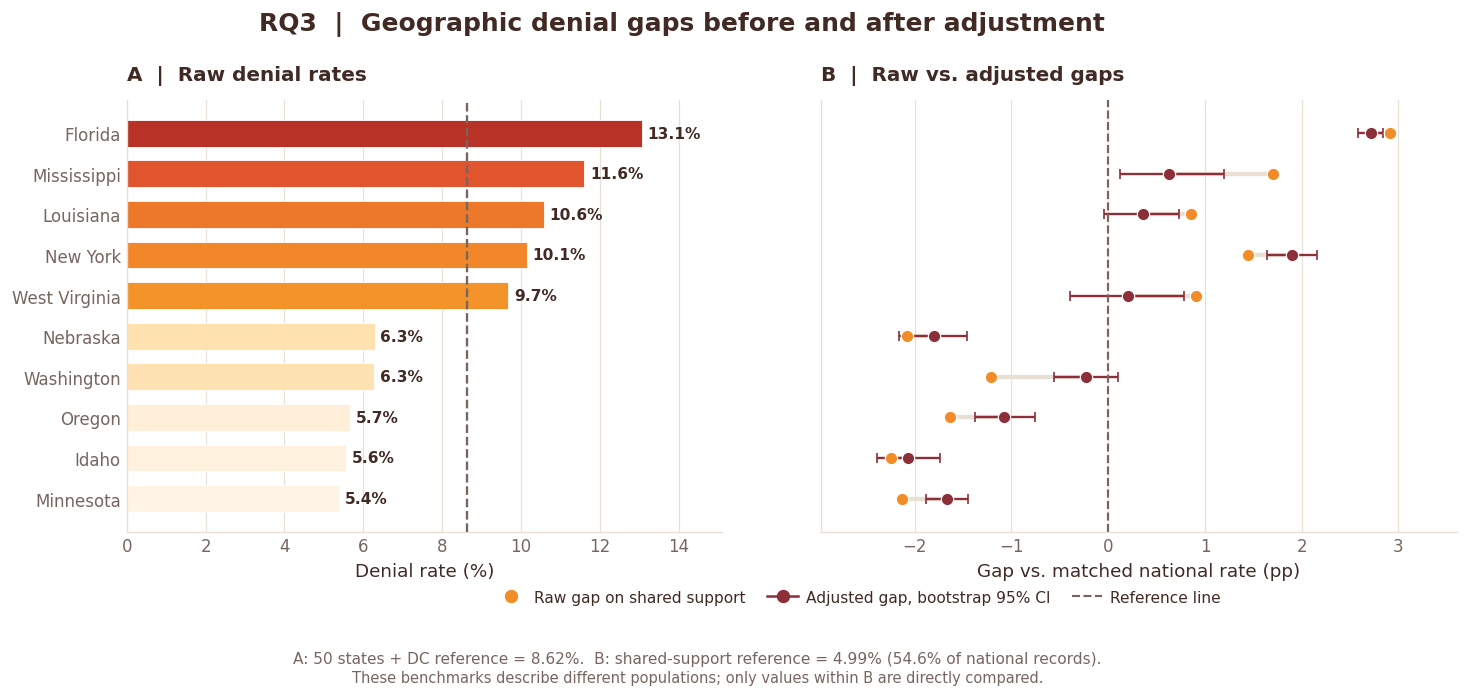

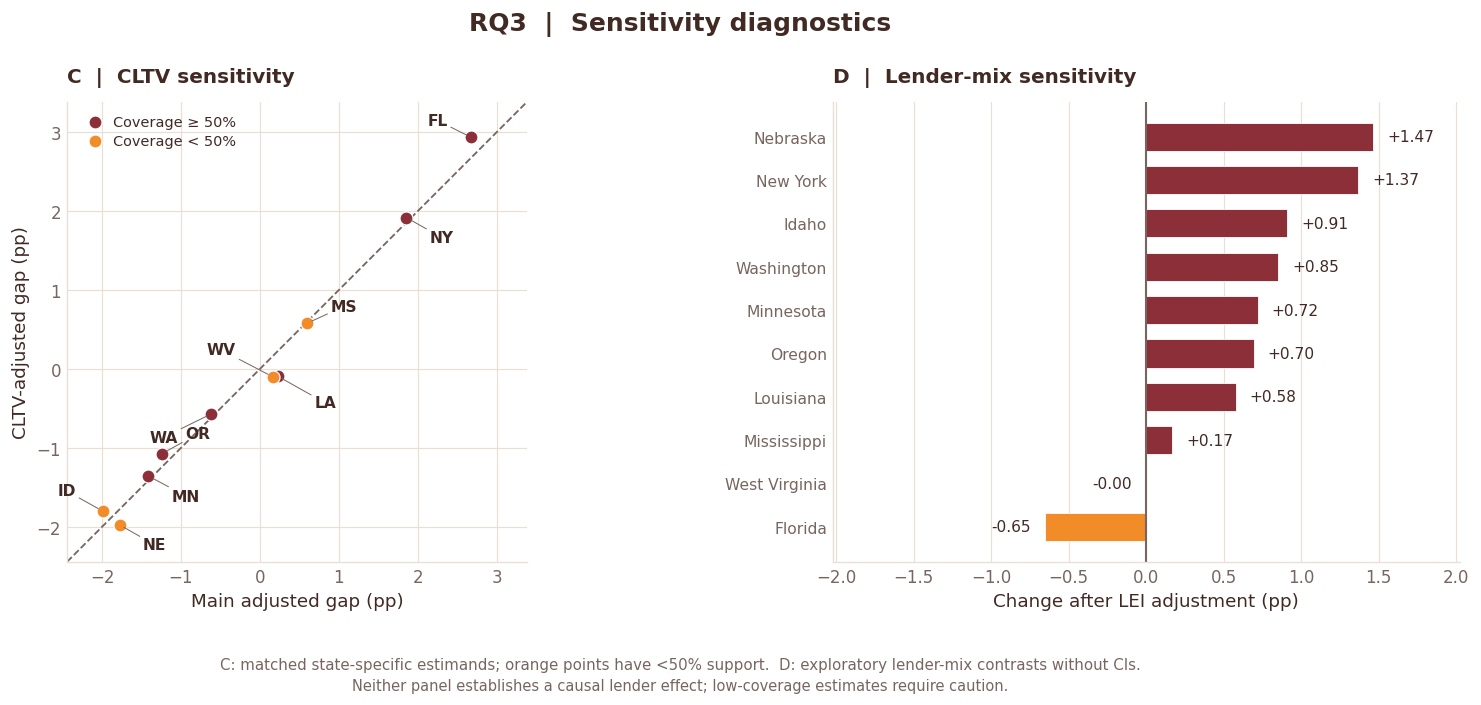


True horizontal multi-panel figures exported at 300 DPI:
rq3_figure_AB_primary.png
rq3_figure_CD_sensitivity.png


In [13]:
# ============================================================
# SECTION 12. PUBLICATION-READY MULTI-PANEL FIGURES
# Genuine side-by-side Matplotlib panels (1 row x 2 columns).
# Group 7 official colours; 300 DPI; no stitched PNG images.
# ============================================================

figure_paths = []


def export_figure(fig, filename):
    target_path = OUTPUT_DIR / filename
    fig.savefig(
        target_path,
        dpi=300,
        bbox_inches="tight",
        facecolor=COLORS["white"],
        pad_inches=0.12
    )
    figure_paths.append(target_path)
    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# MAIN FIGURE: PANEL A (LEFT) AND PANEL B (RIGHT)
# Both panels use the SAME selected states in the SAME order.
# Panel A has the combined 50-states-plus-DC raw benchmark.
# Panel B has the MATCHED shared-support benchmark (not 8.62%).
# ------------------------------------------------------------

plot_data = focus_results.sort_values("raw_denial_rate").copy()
plot_data["state_label"] = (
    plot_data["state_code"].map(STATE_NAMES).fillna(plot_data["state_code"])
)
ypos = np.arange(len(plot_data))

fig, (ax_a, ax_b) = plt.subplots(
    nrows=1, ncols=2,
    figsize=(13.4, 5.8),
    sharey=True,
    gridspec_kw={"width_ratios": [1.04, 1.11]}
)

# A. Raw state denial rates, full geographic benchmark.
rates_pct = 100.0 * plot_data["raw_denial_rate"].to_numpy(dtype=float)
normalizer = Normalize(vmin=float(rates_pct.min()), vmax=float(rates_pct.max()))
bar_colors = [HEATMAP_CMAP(normalizer(value)) for value in rates_pct]
bar_handles = ax_a.barh(
    ypos, rates_pct, color=bar_colors, height=0.66,
    edgecolor=COLORS["white"], linewidth=0.5, zorder=2
)
ax_a.axvline(
    100.0 * float(national_raw_rate),
    color=COLORS["secondary"], linestyle="--", linewidth=1.4,
    zorder=4
)
for bar, value in zip(bar_handles, rates_pct):
    ax_a.text(
        value + 0.14, bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%", va="center", ha="left",
        fontsize=9.2, color=COLORS["text"], fontweight="semibold"
    )
ax_a.set_yticks(ypos)
ax_a.set_yticklabels(plot_data["state_label"], fontsize=10.0)
ax_a.tick_params(axis="y", labelleft=True, labelright=False, length=0)
ax_a.set_xlim(0, max(15.1, float(rates_pct.max()) * 1.14))
ax_a.set_xlabel("Denial rate (%)", fontsize=11)
ax_a.set_title("A  |  Raw denial rates", loc="left", fontsize=12, pad=12)
style_statistical_axes(ax_a, "x")

# B. Shared-support raw gap vs. adjusted gap + bootstrap uncertainty.
raw_gap = plot_data["matched_support_raw_gap_pp"].to_numpy(dtype=float)
adj_gap = plot_data["adjusted_gap_pp"].to_numpy(dtype=float)
ci_lower = plot_data["adjusted_gap_ci_lower_pp"].to_numpy(dtype=float)
ci_upper = plot_data["adjusted_gap_ci_upper_pp"].to_numpy(dtype=float)

for y, raw, adjusted in zip(ypos, raw_gap, adj_gap):
    ax_b.plot(
        [raw, adjusted], [y, y],
        color=COLORS["grid"], linewidth=2.6, zorder=1
    )
ax_b.errorbar(
    adj_gap, ypos,
    xerr=np.vstack([
        np.maximum(adj_gap - ci_lower, 0),
        np.maximum(ci_upper - adj_gap, 0),
    ]),
    fmt="none", ecolor=COLORS["burgundy"],
    elinewidth=1.4, capsize=3.1, zorder=2
)
ax_b.scatter(
    raw_gap, ypos, s=55, color=COLORS["orange"],
    edgecolor=COLORS["white"], linewidth=0.7,
    zorder=3, label="Raw gap"
)
ax_b.scatter(
    adj_gap, ypos, s=55, color=COLORS["burgundy"],
    edgecolor=COLORS["white"], linewidth=0.7,
    zorder=4, label="Adjusted gap (95% CI)"
)
ax_b.axvline(0, color=COLORS["secondary"], linestyle="--", linewidth=1.3)
ax_b.set_yticks(ypos)
ax_b.tick_params(axis="y", left=False, labelleft=False, labelright=False)
all_gaps = np.concatenate([raw_gap, adj_gap, ci_lower, ci_upper])
gap_span = max(1.0, float(np.ptp(all_gaps)))
ax_b.set_xlim(
    float(all_gaps.min()) - 0.11 * gap_span,
    float(all_gaps.max()) + 0.13 * gap_span
)
ax_b.set_xlabel("Gap vs. matched national rate (pp)", fontsize=11)
ax_b.set_title("B  |  Raw vs. adjusted gaps", loc="left", fontsize=12, pad=12)
style_statistical_axes(ax_b, "x")

shared_coverage = float(
    focus_common_diagnostics.loc[0, "national_weight_covered"]
)
shared_reference = float(
    focus_common_diagnostics.loc[0, "shared_national_reference_rate"]
)

fig.suptitle(
    "RQ3  |  Geographic denial gaps before and after adjustment",
    fontsize=15, fontweight="bold", y=0.978
)
fig.legend(
    handles=[
        Line2D([0], [0], marker="o", linestyle="none", markersize=7,
               color=COLORS["orange"], label="Raw gap on shared support"),
        Line2D([0], [0], marker="o", linestyle="-", markersize=7,
               color=COLORS["burgundy"], label="Adjusted gap, bootstrap 95% CI"),
        Line2D([0], [0], linestyle="--", linewidth=1.3,
               color=COLORS["secondary"], label="Reference line"),
    ],
    loc="lower center", bbox_to_anchor=(0.61, 0.105),
    ncol=3, frameon=False, fontsize=9.2,
    handletextpad=0.5, columnspacing=1.4
)
fig.text(
    0.51, 0.041,
    (
        f"A: 50 states + DC reference = {national_raw_rate:.2%}.  "
        f"B: shared-support reference = {shared_reference:.2%} "
        f"({shared_coverage:.1%} of national records)."
    ),
    ha="center", fontsize=9.2, color=COLORS["secondary"]
)
fig.text(
    0.51, 0.014,
    "These benchmarks describe different populations; only values within B are directly compared.",
    ha="center", fontsize=8.8, color=COLORS["secondary"]
)
fig.subplots_adjust(left=0.155, right=0.982, top=0.85, bottom=0.23, wspace=0.16)
export_figure(fig, "rq3_figure_AB_primary.png")


# ------------------------------------------------------------
# SUPPLEMENTARY FIGURE: PANEL C (LEFT) AND PANEL D (RIGHT)
# Two independent panels on the SAME horizontal canvas.
# ------------------------------------------------------------

fig, (ax_c, ax_d) = plt.subplots(
    nrows=1, ncols=2, figsize=(13.4, 5.9),
    gridspec_kw={"width_ratios": [0.98, 1.08]}
)

# C. Scatter compares the main and CLTV state-specific estimates.
cltv_plot = focus_results[
    ["state_code", "state_specific_adjusted_gap_pp",
     "cltv_adjusted_gap_pp", "cltv_common_support_coverage"]
].dropna().copy()
cltv_plot["low_coverage"] = (
    cltv_plot["cltv_common_support_coverage"] < LOW_SUPPORT_WARNING_THRESHOLD
)

for is_low, color, label in [
    (False, COLORS["burgundy"], "Coverage ≥ 50%"),
    (True, COLORS["orange"], "Coverage < 50%"),
]:
    points = cltv_plot.loc[cltv_plot["low_coverage"] == is_low]
    if not points.empty:
        ax_c.scatter(
            points["state_specific_adjusted_gap_pp"],
            points["cltv_adjusted_gap_pp"],
            s=61, color=color, edgecolor=COLORS["white"],
            linewidth=0.75, label=label, zorder=3
        )

x_main = cltv_plot["state_specific_adjusted_gap_pp"].to_numpy(dtype=float)
y_cltv = cltv_plot["cltv_adjusted_gap_pp"].to_numpy(dtype=float)
axis_lo = min(float(x_main.min()), float(y_cltv.min())) - 0.45
axis_hi = max(float(x_main.max()), float(y_cltv.max())) + 0.45
ax_c.plot([axis_lo, axis_hi], [axis_lo, axis_hi],
          linestyle="--", color=COLORS["secondary"], linewidth=1.1)
ax_c.set_xlim(axis_lo, axis_hi)
ax_c.set_ylim(axis_lo, axis_hi)
ax_c.set_aspect("equal", adjustable="box")

# Explicit label offsets use two-letter state codes and avoid crowded
# full-state names on the narrower left panel. Coverage is encoded by colour.
label_offsets = {
    "FL": (-14, 10), "NY": (14, -12), "MS": (14, 10),
    "LA": (22, -16), "WV": (-22, 16), "NE": (14, -12),
    "WA": (-20, -14), "OR": (14, 12), "ID": (-16, 12),
    "MN": (14, -12),
}
for row in cltv_plot.itertuples(index=False):
    dx, dy = label_offsets.get(row.state_code, (8, 8))
    ax_c.annotate(
        row.state_code,
        xy=(row.state_specific_adjusted_gap_pp, row.cltv_adjusted_gap_pp),
        xytext=(dx, dy), textcoords="offset points",
        ha="right" if dx < 0 else "left",
        va="center", fontsize=9.3, color=COLORS["text"],
        fontweight="semibold", zorder=4,
        arrowprops=dict(arrowstyle="-", color=COLORS["secondary"], lw=0.6, shrinkA=0, shrinkB=3),
    )
ax_c.set_xlabel("Main adjusted gap (pp)", fontsize=11)
ax_c.set_ylabel("CLTV-adjusted gap (pp)", fontsize=11)
ax_c.set_title("C  |  CLTV sensitivity", loc="left", fontsize=12, pad=12)
ax_c.legend(
    loc="upper left", frameon=False, fontsize=8.7,
    labelspacing=0.35, handletextpad=0.3
)
style_statistical_axes(ax_c, "both")

# D. Lender-mix contrast, sign indicated by colour, no implied CI.
if lender_focus_results.empty:
    ax_d.text(
        0.5, 0.5, "Lender-mix results unavailable",
        transform=ax_d.transAxes, ha="center", va="center"
    )
    ax_d.axis("off")
else:
    lender_plot = lender_focus_results.sort_values(
        "gap_change_after_lei_pp"
    ).copy()
    lender_plot["state_label"] = (
        lender_plot["state_code"].map(STATE_NAMES)
        .fillna(lender_plot["state_code"])
    )
    vals = lender_plot["gap_change_after_lei_pp"].to_numpy(dtype=float)
    yy = np.arange(len(lender_plot))
    bar_colors = [
        COLORS["burgundy"] if v >= 0 else COLORS["orange"]
        for v in vals
    ]
    lender_bars = ax_d.barh(
        yy, vals, color=bar_colors, height=0.65,
        edgecolor=COLORS["white"], linewidth=0.5, zorder=2
    )
    ax_d.set_yticks(yy)
    ax_d.set_yticklabels(lender_plot["state_label"], fontsize=9.3)
    ax_d.axvline(0, color=COLORS["secondary"], linewidth=1.25)
    xmax = max(0.25, float(np.abs(vals).max()))
    ax_d.set_xlim(-1.38 * xmax, 1.38 * xmax)
    for bar, value in zip(lender_bars, vals):
        ax_d.text(
            value + (0.06 * xmax if value >= 0 else -0.06 * xmax),
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.2f}",
            ha="left" if value >= 0 else "right",
            va="center", fontsize=9.2, color=COLORS["text"]
        )
    ax_d.set_xlabel("Change after LEI adjustment (pp)", fontsize=11)
    ax_d.set_title("D  |  Lender-mix sensitivity", loc="left", fontsize=12, pad=12)
    style_statistical_axes(ax_d, "x")

fig.suptitle(
    "RQ3  |  Sensitivity diagnostics",
    fontsize=15, fontweight="bold", y=0.978
)
fig.text(
    0.5, 0.048,
    "C: matched state-specific estimands; orange points have <50% support.  "
    "D: exploratory lender-mix contrasts without CIs.",
    ha="center", fontsize=9, color=COLORS["secondary"]
)
fig.text(
    0.5, 0.019,
    "Neither panel establishes a causal lender effect; low-coverage estimates require caution.",
    ha="center", fontsize=8.8, color=COLORS["secondary"]
)
fig.subplots_adjust(left=0.085, right=0.985, top=0.85, bottom=0.20, wspace=0.42)
export_figure(fig, "rq3_figure_CD_sensitivity.png")

print("\nTrue horizontal multi-panel figures exported at 300 DPI:")
for path in figure_paths:
    print(path.name)


## 13. Export reproducible result tables

Outputs are saved to `hmda/results/rq3` in the shared Drive folder. State-specific tables include minimum-count and common-support warnings; the ten-state primary results use matched shared support. The two figure files are generated only in Section 12. No source Parquet data are changed.


In [14]:
# The figure cell has already exported the two final multi-panel figures.
# Export tables without recomputing or overwriting figures.
raw_state_rates.to_csv(OUTPUT_DIR / "rq3_raw_state_denial_rates.csv", index=False)
eligible_states.to_csv(OUTPUT_DIR / "rq3_eligible_states_10000_decisions.csv", index=False)
focus_states.to_csv(OUTPUT_DIR / "rq3_focus_states_top_bottom_five.csv", index=False)
main_direct_export.to_csv(OUTPUT_DIR / "rq3_direct_standardization_all_states.csv", index=False)
main_bootstrap_ci.to_csv(OUTPUT_DIR / "rq3_direct_standardization_bootstrap_ci.csv", index=False)
model_based_results.to_csv(OUTPUT_DIR / "rq3_model_based_standardization.csv", index=False)
cltv_direct_export.to_csv(OUTPUT_DIR / "rq3_cltv_sensitivity_direct_standardization.csv", index=False)
cltv_bootstrap_ci.to_csv(OUTPUT_DIR / "rq3_cltv_sensitivity_bootstrap_ci.csv", index=False)
main_results.to_csv(OUTPUT_DIR / "rq3_combined_results_all_eligible_states.csv", index=False)
focus_results.to_csv(OUTPUT_DIR / "rq3_combined_results_focus_states.csv", index=False)
lender_mix_results.to_csv(OUTPUT_DIR / "rq3_lender_mix_comparison.csv", index=False)
focus_matched_raw.to_csv(OUTPUT_DIR / "rq3_matched_support_raw_gaps.csv", index=False)
estimator_robustness.to_csv(
    OUTPUT_DIR / "rq3_estimator_robustness_focus_states.csv", index=False
)
model_shared_results.to_csv(
    OUTPUT_DIR / "rq3_model_based_on_shared_support.csv", index=False
)
focus_common_diagnostics.to_csv(OUTPUT_DIR / "rq3_shared_support_diagnostics.csv", index=False)
focus_common_direct.to_csv(OUTPUT_DIR / "rq3_shared_support_direct_standardization.csv", index=False)
focus_common_bootstrap_ci.to_csv(OUTPUT_DIR / "rq3_shared_support_bootstrap_ci.csv", index=False)

# Pooling diagnostics.
pooling_diagnostics = pd.concat(
    [
        main_pooling.assign(specification="Main four-dimensional strata"),
        cltv_pooling.assign(specification="CLTV sensitivity strata")
    ],
    ignore_index=True
)
pooling_diagnostics.to_csv(
    OUTPUT_DIR / "rq3_sparse_strata_pooling_diagnostics.csv", index=False
)

print("Final figures already saved by Section 12:")
for path in figure_paths:
    print(path.name)

# Save Pandas-PySpark correctness outputs when Spark validation completed.
if not spark_validation_summary.empty:
    spark_validation_summary.to_csv(
        OUTPUT_DIR / "rq3_pandas_spark_correctness_summary.csv",
        index=False
    )
    missing_compare.to_csv(
        OUTPUT_DIR / "rq3_pandas_spark_missing_value_comparison.csv",
        index=False
    )
    raw_compare.to_csv(
        OUTPUT_DIR / "rq3_pandas_spark_state_rate_comparison.csv",
        index=False
    )
    mean_compare.to_csv(
        OUTPUT_DIR / "rq3_pandas_spark_mean_loan_amount_comparison.csv",
        index=False
    )
    direct_compare.to_csv(
        OUTPUT_DIR / "rq3_pandas_spark_standardized_gap_comparison.csv",
        index=False
    )
    shared_compare.to_csv(
        OUTPUT_DIR / "rq3_pandas_spark_shared_support_gap_comparison.csv",
        index=False
    )


OUTPUT_NOTES = """# Group 7 — RQ3 output definitions

- Cohort: 50 U.S. states + Washington, D.C. (in-scope 2024 HMDA applications). Territories and unknown state codes excluded from state-reference analyses.
- Raw geographic benchmark: combined denial rate from that cohort; recalculated from the cleaned dataset (approximately 8.62%).
- Focus-state rule: five highest and five lowest raw state denial rates among the 42 eligible states. DC is in the *reference population* but does not meet the ranking threshold.
- Primary figure AB: Panel A uses the full-cohort raw reference. Panel B uses a separate national reference conditional on identical shared-support strata; Panel B raw/adjusted values alone can be compared as a before/after adjustment.
- State-specific CSVs: adjusted gaps can have different national reference rates across jurisdictions, and MUST NOT be ranked as directly comparable; review_flags indicate low decisions and/or less than 50% national-weight support. The 50% flag is a reporting heuristic, not a statistical test.
- CLTV sensitivity: additional stratum dimension with Missing retained; compared against the state-specific main estimate, not the 10-state shared-support estimate.
- Model-based robustness: original full-distribution model estimates AND aligned shared-support model estimates are separately exported. Differences between estimators have no model-based CI and are not causal.
- Lender mix: comparison is restricted to cross-jurisdiction LEIs with observed overlap; sign reversal does not imply statistical significance. No lender-mix contrast CI was calculated.
- Bootstrap: 500 repetitions for direct adjusted gaps, conditional on the fixed selected focus states and fixed shared-support strata; selection uncertainty is not included.
- Correctness: Pandas and Spark use the same cleaned input and agreed pooling rule. Both state-specific and main shared-support gaps are checked.
- Supplementary Figure CD is exploratory. Figures are exported at 300 DPI with Group 7 colors.
"""
(OUTPUT_DIR / "rq3_output_notes.md").write_text(OUTPUT_NOTES, encoding="utf-8")
print("Output definitions saved as rq3_output_notes.md")


Final figures already saved by Section 12:
rq3_figure_AB_primary.png
rq3_figure_CD_sensitivity.png
Output definitions saved as rq3_output_notes.md


## 14. Reproducibility and final RQ3 summary

The summary below prints the reference population, common-support coverage, estimator sensitivity, lender-mix caveats, and Pandas–Spark checks. The national raw rate and the shared-support rate are different quantities. Interpret each comparison in its own population; do not describe changes as causal effects, statistical proof of discrimination, or a complete decomposition of financial vs. geographic factors.


In [15]:

print("=" * 72)
print("RQ3 — FINAL DIAGNOSTIC ANALYSIS SUMMARY")
print("=" * 72)

print(f"Analytical records across 50 states + DC: {len(analysis):,}")
print(f"National raw denial rate (50 states + DC): {national_raw_rate:.4%}")
print(f"States with at least {MIN_STATE_DECISIONS:,} decisions: {len(eligible_states)}")

print(
    f"Main original strata: "
    f"{main_pooling.loc[0, 'original_strata']:,}"
)

print(
    "Main original sparse strata pooled: "
    f"{main_pooling.loc[0, 'original_strata_with_n_below_threshold']:,}"
)

print(
    "Share of records in pooled sparse strata: "
    f"{main_pooling.loc[0, 'pooled_sparse_record_share']:.2%}"
)

print(
    "CLTV sensitivity sparse-strata record share: "
    f"{cltv_pooling.loc[0, 'pooled_sparse_record_share']:.2%}"
)

# Focus-state comparison
print("\nFocus-state comparison:")
print("Compare matched_support_raw_gap_pp directly with adjusted_gap_pp; both use the same shared-support population.")

display(
    focus_results[
        [
            "state_code",
            "decisions",
            "raw_denial_rate",
            "raw_gap_pp",
            "matched_support_state_decision_share",
            "state_specific_adjusted_gap_pp",
            "matched_support_raw_gap_pp",
            "adjusted_gap_pp",
            "adjusted_gap_ci_lower_pp",
            "adjusted_gap_ci_upper_pp",
            "common_support_coverage",
            "model_based_adjusted_gap_pp",
            "model_shared_gap_pp",
            "method_difference_on_shared_support_pp",
            "cltv_adjusted_gap_pp",
            "cltv_common_support_coverage",
            "cltv_vs_state_specific_gap_change_pp"
        ]
    ].sort_values(
        "raw_denial_rate",
        ascending=False
    ).style.format({
        "raw_denial_rate": "{:.2%}",
        "raw_gap_pp": "{:+.2f} pp",
        "matched_support_raw_gap_pp": "{:+.2f} pp",
        "matched_support_state_decision_share": "{:.1%}",
        "state_specific_adjusted_gap_pp": "{:+.2f} pp",
        "adjusted_gap_pp": "{:+.2f} pp",
        "adjusted_gap_ci_lower_pp": "{:+.2f} pp",
        "adjusted_gap_ci_upper_pp": "{:+.2f} pp",
        "common_support_coverage": "{:.1%}",
        "model_based_adjusted_gap_pp": "{:+.2f} pp",
        "model_shared_gap_pp": "{:+.2f} pp",
        "method_difference_on_shared_support_pp": "{:+.2f} pp",
        "cltv_adjusted_gap_pp": "{:+.2f} pp",
        "cltv_common_support_coverage": "{:.1%}",
        "cltv_vs_state_specific_gap_change_pp": "{:+.2f} pp"
    })
)

# Lender-mix comparison
print("\nLender-mix comparison for focus states:")

if lender_focus_results.empty:
    print("No lender-mix estimates were produced.")
else:
    display(
        lender_focus_results[
            [
                "state_code",
                "state_share_covered_by_cross_state_leis",
                "cross_state_leis_active_in_state",
                "gap_without_lei_pp",
                "gap_with_lei_pp",
                "gap_change_after_lei_pp"
            ]
        ].style.format({
            "state_share_covered_by_cross_state_leis": "{:.1%}",
            "gap_without_lei_pp": "{:+.2f} pp",
            "gap_with_lei_pp": "{:+.2f} pp",
            "gap_change_after_lei_pp": "{:+.2f} pp"
        })
    )

# Pandas-PySpark correctness status
print("\nPandas-PySpark correctness status:")

if not spark_validation_summary.empty:
    display(spark_validation_summary)

    print(
        "All correctness checks passed:",
        bool(spark_validation_summary["passed"].all())
    )
else:
    print("PySpark validation was not completed.")

    if spark_validation_error:
        print(spark_validation_error)

print("\nShared-support fraction of national records:",
      f"{focus_common_diagnostics.loc[0, 'national_weight_covered']:.2%}")
print("National reference rate on shared support:",
      f"{focus_common_diagnostics.loc[0, 'shared_national_reference_rate']:.2%}")
print("The raw 50-states-plus-DC benchmark is not the shared-support reference.")
print("Main direct and model-based estimates differ by estimator and/or scope.")
print("Lender-mix changes are exploratory and have no contrast CI.")
print("\nOutput directory:", OUTPUT_DIR)
print("RQ3 analysis completed.")


RQ3 — FINAL DIAGNOSTIC ANALYSIS SUMMARY
Analytical records across 50 states + DC: 3,119,941
National raw denial rate (50 states + DC): 8.6179%
States with at least 10,000 decisions: 42
Main original strata: 1,236
Main original sparse strata pooled: 331
Share of records in pooled sparse strata: 0.09%
CLTV sensitivity sparse-strata record share: 0.74%

Focus-state comparison:
Compare matched_support_raw_gap_pp directly with adjusted_gap_pp; both use the same shared-support population.


,state_code,decisions,raw_denial_rate,raw_gap_pp,matched_support_state_decision_share,state_specific_adjusted_gap_pp,matched_support_raw_gap_pp,adjusted_gap_pp,adjusted_gap_ci_lower_pp,adjusted_gap_ci_upper_pp,common_support_coverage,model_based_adjusted_gap_pp,model_shared_gap_pp,method_difference_on_shared_support_pp,cltv_adjusted_gap_pp,cltv_common_support_coverage,cltv_vs_state_specific_gap_change_pp
0,FL,273741,13.07%,+4.45 pp,55.3%,+2.67 pp,+2.91 pp,+2.72 pp,+2.58 pp,+2.84 pp,54.6%,+2.47 pp,+2.33 pp,-0.39 pp,+2.94 pp,89.8%,+0.26 pp
4,MS,22059,11.61%,+2.99 pp,43.8%,+0.60 pp,+1.70 pp,+0.62 pp,+0.12 pp,+1.20 pp,54.6%,+0.04 pp,+0.03 pp,-0.59 pp,+0.58 pp,34.3%,-0.02 pp
2,LA,33117,10.58%,+1.96 pp,46.2%,+0.23 pp,+0.86 pp,+0.36 pp,-0.05 pp,+0.74 pp,54.6%,-0.06 pp,-0.06 pp,-0.42 pp,-0.09 pp,50.7%,-0.32 pp
6,NY,105410,10.15%,+1.53 pp,53.9%,+1.86 pp,+1.44 pp,+1.90 pp,+1.64 pp,+2.16 pp,54.6%,+1.51 pp,+1.42 pp,-0.48 pp,+1.92 pp,76.4%,+0.06 pp
9,WV,13833,9.67%,+1.05 pp,49.4%,+0.16 pp,+0.90 pp,+0.21 pp,-0.39 pp,+0.79 pp,54.6%,-0.22 pp,-0.21 pp,-0.42 pp,-0.10 pp,22.4%,-0.26 pp
5,NE,18863,6.29%,-2.33 pp,62.8%,-1.78 pp,-2.08 pp,-1.80 pp,-2.16 pp,-1.46 pp,54.6%,-0.66 pp,-0.62 pp,+1.19 pp,-1.98 pp,42.4%,-0.20 pp
8,WA,73763,6.28%,-2.34 pp,44.8%,-0.62 pp,-1.21 pp,-0.23 pp,-0.57 pp,+0.10 pp,54.6%,-1.04 pp,-0.97 pp,-0.74 pp,-0.57 pp,66.2%,+0.05 pp
7,OR,37794,5.66%,-2.96 pp,55.0%,-1.24 pp,-1.63 pp,-1.08 pp,-1.37 pp,-0.75 pp,54.6%,-0.89 pp,-0.83 pp,+0.26 pp,-1.07 pp,57.0%,+0.16 pp
1,ID,22533,5.56%,-3.06 pp,56.3%,-1.99 pp,-2.24 pp,-2.07 pp,-2.39 pp,-1.74 pp,54.6%,-0.81 pp,-0.76 pp,+1.31 pp,-1.80 pp,47.7%,+0.19 pp
3,MN,56827,5.39%,-3.22 pp,70.6%,-1.41 pp,-2.13 pp,-1.66 pp,-1.88 pp,-1.45 pp,54.6%,-1.28 pp,-1.18 pp,+0.48 pp,-1.36 pp,70.6%,+0.06 pp



Lender-mix comparison for focus states:


,state_code,state_share_covered_by_cross_state_leis,cross_state_leis_active_in_state,gap_without_lei_pp,gap_with_lei_pp,gap_change_after_lei_pp
7,FL,97.9%,1038,+2.52 pp,+1.87 pp,-0.65 pp
10,ID,99.0%,338,-2.97 pp,-2.06 pp,+0.91 pp
15,LA,98.8%,367,-0.34 pp,+0.23 pp,+0.58 pp
20,MN,99.4%,451,-2.55 pp,-1.83 pp,+0.72 pp
22,MS,99.8%,352,+0.30 pp,+0.47 pp,+0.17 pp
24,NE,99.5%,287,-2.72 pp,-1.25 pp,+1.47 pp
29,NY,93.5%,316,+0.70 pp,+2.06 pp,+1.37 pp
32,OR,99.5%,415,-2.23 pp,-1.53 pp,+0.70 pp
39,WA,99.0%,494,-1.78 pp,-0.92 pp,+0.85 pp
41,WV,99.2%,316,-0.42 pp,-0.43 pp,-0.00 pp



Pandas-PySpark correctness status:


,output,max_absolute_difference,tolerance,passed
0,Total record count,0.000000e+00,0.000000,True
1,Missing-value counts across all columns,0.000000e+00,0.000000,True
2,State denial counts,0.000000e+00,0.000000,True
3,State denial rates,0.000000e+00,0.000001,True
4,Mean loan amount by loan type,0.000000e+00,0.010000,True
5,Shared-support focus-state standardized gaps (...,2.220446e-16,0.000001,True
6,Direct standardized state gaps (proportions),1.526557e-16,0.000001,True


All correctness checks passed: True

Shared-support fraction of national records: 54.56%
National reference rate on shared support: 4.99%
The raw 50-states-plus-DC benchmark is not the shared-support reference.
Main direct and model-based estimates differ by estimator and/or scope.
Lender-mix changes are exploratory and have no contrast CI.

Output directory: /content/drive/MyDrive/hmda/results/rq3
RQ3 analysis completed.
